# Week 6: Natural Language Processing - Advanced Edition
## Complete Guide with Practical Examples & Advanced Techniques

### Table of Contents
1. **Setup & Installation** - Install required NLP libraries
2. **Text Preprocessing** - Clean and prepare text data
   - Lowercasing & Normalization
   - Punctuation & Special Character Removal
   - Number Removal
   - Stopword Removal
3. **Tokenization** - Break text into tokens
   - Word Tokenization
   - Sentence Tokenization
4. **Advanced Text Processing** - Grammar & meaning extraction
   - POS Tagging
   - Named Entity Recognition (NER)
   - Chunking & Chinking
   - Lemmatization
5. **Feature Engineering** - Convert text to numerical representations
   - Bag of Words (BoW)
   - TF-IDF (Term Frequency-Inverse Document Frequency)
   - Word Embeddings (Word2Vec)
6. **Text Analysis** - Understand text properties
   - Document Similarity (Cosine Similarity)
   - Sentiment Analysis
   - Text Statistics & Visualization
7. **Text Classification** - Classify documents into categories
   - Naive Bayes Classifier
   - Model Evaluation & Metrics
8. **Best Practices & Utilities** - Professional NLP workflows

In [1]:
!pip install nltk spacy scikit-learn textblob gensim matplotlib seaborn wordcloud -q

In [2]:
# ============== IMPORTS & SETUP ==============
import nltk
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
import re
import string
import warnings
warnings.filterwarnings('ignore')

# Set up visualization style
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 5)

# ============== UTILITY FUNCTIONS ==============
def create_word_frequency_chart(text, top_n=15):
    """Create a word frequency visualization"""
    from nltk.tokenize import word_tokenize
    from nltk.corpus import stopwords
    
    stop_words = set(stopwords.words('english'))
    words = [w.lower() for w in word_tokenize(text) if w.isalnum() and w.lower() not in stop_words]
    
    freq = Counter(words)
    top_words = dict(freq.most_common(top_n))
    
    plt.figure(figsize=(12, 5))
    plt.bar(top_words.keys(), top_words.values(), color='steelblue')
    plt.xlabel('Words')
    plt.ylabel('Frequency')
    plt.title(f'Top {top_n} Most Frequent Words')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()
    
    return top_words

def text_statistics(text):
    """Generate comprehensive text statistics"""
    words = text.split()
    sentences = text.split('.')
    chars = len(text)
    
    stats = {
        'Total Characters': chars,
        'Total Words': len(words),
        'Total Sentences': len([s for s in sentences if s.strip()]),
        'Average Word Length': np.mean([len(w) for w in words]),
        'Unique Words': len(set(w.lower() for w in words)),
        'Lexical Diversity': len(set(w.lower() for w in words)) / len(words)
    }
    return stats

print("✓ All imports loaded successfully!")
print("✓ Utility functions ready to use!")

✓ All imports loaded successfully!
✓ Utility functions ready to use!


In [3]:
import nltk
nltk.download('punkt')

# Example 1
text = "Hello WORLD"
print(text.lower())  # hello world

# Example 2
text = "Python is AWESOME!!!"
print(text.lower())  # python is awesome!!!

# Example 3
text = "I Love NLP"
print(text.lower())  # i love nlp

# Example 4
text = "Data SCIENCE 101"
print(text.lower())  # data science 101

# Example 5
text = "GOOD Morning"
print(text.lower())  # good morning

hello world
python is awesome!!!
i love nlp
data science 101
good morning


[nltk_data] Downloading package punkt to C:\Users\Haseeb
[nltk_data]     Salman\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!


In [4]:
import string

# Example 1
text = "Hello, world!"
clean = ''.join(char for char in text if char not in string.punctuation)
print(clean)  # Hello world

# Example 2
text = "What's your name?"
clean = ''.join(char for char in text if char not in string.punctuation)
print(clean)  # Whats your name

# Example 3
text = "Wow!!! This is great."
clean = ''.join(char for char in text if char not in string.punctuation)
print(clean)  # Wow This is great

# Example 4
text = "Python: easy; fun!"
clean = ''.join(char for char in text if char not in string.punctuation)
print(clean)  # Python easy fun

# Example 5
text = "Hello (world) [NLP]"
clean = ''.join(char for char in text if char not in string.punctuation)
print(clean)  # Hello world NLP

Hello world
Whats your name
Wow This is great
Python easy fun
Hello world NLP


In [5]:
from nltk.corpus import stopwords
nltk.download('stopwords')
stop_words = set(stopwords.words('english'))

# Example 1
text = "this is a simple sentence"
words = text.split()
clean = [w for w in words if w not in stop_words]
print(clean)  # ['simple', 'sentence']

# Example 2
text = "the cat is sleeping on the mat"
words = text.split()
clean = [w for w in words if w not in stop_words]
print(clean)  # ['cat', 'sleeping', 'mat']

# Example 3
text = "i love to eat pizza and pasta"
words = text.split()
clean = [w for w in words if w not in stop_words]
print(clean)  # ['love', 'eat', 'pizza', 'pasta']

# Example 4
text = "he was very happy because he won"
words = text.split()
clean = [w for w in words if w not in stop_words]
print(clean)  # ['happy', 'won']

# Example 5
text = "we are going to the market"
words = text.split()
clean = [w for w in words if w not in stop_words]
print(clean)  # ['going', 'market']

['simple', 'sentence']
['cat', 'sleeping', 'mat']
['love', 'eat', 'pizza', 'pasta']
['happy']
['going', 'market']


[nltk_data] Downloading package stopwords to C:\Users\Haseeb
[nltk_data]     Salman\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [6]:
import nltk

# FIRST: Download required resources (run this once)
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')

# Now your tokenization code will work
from nltk.tokenize import word_tokenize, sent_tokenize

# Word tokenization examples
print("=== Word Tokenization ===")

# Example 1
text = "Hello world!"
print(word_tokenize(text))  # ['Hello', 'world', '!']

# Example 2
text = "I'm learning NLP."
print(word_tokenize(text))  # ['I', "'m", 'learning', 'NLP', '.']

# Example 3
text = "Let's eat, mom!"
print(word_tokenize(text))  # ['Let', "'s", 'eat', ',', 'mom', '!']

# Sentence tokenization examples
print("\n=== Sentence Tokenization ===")

# Example 4
text = "Hello world. How are you?"
print(sent_tokenize(text))  # ['Hello world.', 'How are you?']

# Example 5
text = "Python is fun. NLP is awesome. Let's code!"
print(sent_tokenize(text))  # ['Python is fun.', 'NLP is awesome.', "Let's code!"]

[nltk_data] Downloading package punkt to C:\Users\Haseeb
[nltk_data]     Salman\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to C:\Users\Haseeb
[nltk_data]     Salman\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to C:\Users\Haseeb
[nltk_data]     Salman\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


=== Word Tokenization ===
['Hello', 'world', '!']
['I', "'m", 'learning', 'NLP', '.']
['Let', "'s", 'eat', ',', 'mom', '!']

=== Sentence Tokenization ===
['Hello world.', 'How are you?']
['Python is fun.', 'NLP is awesome.', "Let's code!"]


In [7]:
import re

# Example 1 - Remove numbers
text = "I have 10 apples and 5 oranges"
clean = re.sub(r'\d+', '', text)
print(clean)  # I have  apples and  oranges

# Example 2 - Remove special characters
text = "Hello @world! #NLP $100"
clean = re.sub(r'[^a-zA-Z\s]', '', text)
print(clean)  # Hello world NLP

# Example 3 - Remove hashtags and mentions
text = "Follow @user and #trending now"
clean = re.sub(r'[@#]\w+', '', text)
print(clean)  # Follow  and  now

# Example 4 - Remove emojis
text = "I love Python 😍🐍"
clean = re.sub(r'[^\x00-\x7F]+', '', text)
print(clean)  # I love Python

# Example 5 - Remove URLs
text = "Check https://example.com for more info"
clean = re.sub(r'http\S+', '', text)
print(clean)  # Check  for more info

I have  apples and  oranges
Hello world NLP 
Follow  and  now
I love Python 
Check  for more info


### Complete Pipeline Example

In [8]:
import re
import string
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

def clean_text(text):
    # 1. Lowercase
    text = text.lower()
    
    # 2. Remove URLs
    text = re.sub(r'http\S+', '', text)
    
    # 3. Remove numbers
    text = re.sub(r'\d+', '', text)
    
    # 4. Remove punctuation
    text = ''.join(char for char in text if char not in string.punctuation)
    
    # 5. Tokenize
    tokens = word_tokenize(text)
    
    # 6. Remove stopwords
    stop_words = set(stopwords.words('english'))
    tokens = [word for word in tokens if word not in stop_words]
    
    return tokens

# Test it
sample = "I love NLP! Check https://example.com. It's amazing 😱😱😱😱 #Learning"
print(clean_text(sample))  # ['love', 'nlp', 'amazing']

['love', 'nlp', 'check', 'amazing', '😱😱😱😱', 'learning']


### POS Tagging
Assign grammatical tags (noun, verb, etc.)

In [9]:
import nltk
nltk.download('punkt')
from nltk.tokenize import word_tokenize, sent_tokenize

[nltk_data] Downloading package punkt to C:\Users\Haseeb
[nltk_data]     Salman\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!


In [10]:
import nltk
nltk.download('averaged_perceptron_tagger_eng')
text = "I love NLP"
words = word_tokenize(text)

print(nltk.pos_tag(words))

[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     C:\Users\Haseeb Salman\AppData\Roaming\nltk_data...
[nltk_data]   Package averaged_perceptron_tagger_eng is already up-to-
[nltk_data]       date!


[('I', 'PRP'), ('love', 'VBP'), ('NLP', 'RB')]


In [11]:
import nltk
nltk.download('maxent_ne_chunker_tab')
nltk.download('words')

text = "Ali lives in Lahore"
words = word_tokenize(text)
tags = nltk.pos_tag(words)

print(nltk.ne_chunk(tags))

[nltk_data] Downloading package maxent_ne_chunker_tab to
[nltk_data]     C:\Users\Haseeb Salman\AppData\Roaming\nltk_data...
[nltk_data]   Package maxent_ne_chunker_tab is already up-to-date!
[nltk_data] Downloading package words to C:\Users\Haseeb
[nltk_data]     Salman\AppData\Roaming\nltk_data...
[nltk_data]   Package words is already up-to-date!


(S (GPE Ali/NNP) lives/VBZ in/IN (GPE Lahore/NNP))


In [12]:
texts = [
    "Ahmed works at Google",
    "Sara lives in Karachi",
    "Bilal studies at UET",
    "Apple is a big company",
    "Imran Khan is a leader"
]

for t in texts:
    print(nltk.ne_chunk(nltk.pos_tag(word_tokenize(t))))

(S (GPE Ahmed/NNP) works/VBZ at/IN (ORGANIZATION Google/NNP))
(S (PERSON Sara/NNP) lives/VBZ in/IN (GPE Karachi/NNP))
(S (GPE Bilal/NNP) studies/NNS at/IN (ORGANIZATION UET/NNP))
(S (GPE Apple/NNP) is/VBZ a/DT big/JJ company/NN)
(S (PERSON Imran/NNP) (ORGANIZATION Khan/NNP) is/VBZ a/DT leader/NN)


### Chunking & Chinking

 Group words into phrases.


In [13]:

grammar = "NP: {<DT>?<JJ>*<NN>}"

parser = nltk.RegexpParser(grammar)

sentence = "The big dog barked"
tags = nltk.pos_tag(word_tokenize(sentence))

tree = parser.parse(tags)
print(tree)
sentences = [
    "The red car is fast",
    "A small cat sleeps",
    "The tall boy runs",
    "An old man walks",
    "The happy child plays"
]

for s in sentences:
    tags = nltk.pos_tag(word_tokenize(s))
    print(parser.parse(tags))

(S (NP The/DT big/JJ dog/NN) barked/VBD)
(S (NP The/DT red/JJ car/NN) is/VBZ fast/RB)
(S (NP A/DT small/JJ cat/NN) sleeps/NNS)
(S (NP The/DT tall/JJ boy/NN) runs/NNS)
(S (NP An/DT old/JJ man/NN) walks/NNS)
(S (NP The/DT happy/JJ child/NN) plays/NNS)


### Lemmatization

Convert word to dictionary form.


In [14]:
import nltk
from nltk.stem import WordNetLemmatizer

nltk.download('wordnet', quiet=True)

lemmatizer = WordNetLemmatizer()

print(lemmatizer.lemmatize("running", pos='v'))  # run

words = [
    ("cars", "n"),
    ("running", "v"),
    ("better", "a"),
    ("studies", "n"),
    ("went", "v")
]

for word, pos in words:
    print(word, "->", lemmatizer.lemmatize(word, pos=pos))

run
cars -> car
running -> run
better -> good
studies -> study
went -> go


### Bag of Words (BoW)
 Convert text into numeric vectors.

In [15]:


from sklearn.feature_extraction.text import CountVectorizer

texts = ["I love NLP", "NLP is fun"]

vectorizer = CountVectorizer()
X = vectorizer.fit_transform(texts)

print(vectorizer.get_feature_names_out())
print(X.toarray())




['fun' 'is' 'love' 'nlp']
[[0 0 1 1]
 [1 1 0 1]]


In [16]:

docs = [
    "I like AI",
    "AI is future",
    "I love machine learning",
    "Deep learning is powerful",
    "AI AI AI"
]

X = CountVectorizer().fit_transform(docs)
print(X.toarray())

[[1 0 0 0 0 1 0 0 0]
 [1 0 1 1 0 0 0 0 0]
 [0 0 0 0 1 0 1 1 0]
 [0 1 0 1 1 0 0 0 1]
 [3 0 0 0 0 0 0 0 0]]


### Feature Selection & Extraction

 Selecting important features.

In [17]:


from sklearn.feature_extraction.text import TfidfVectorizer

texts = ["I love AI", "AI is the future"]

tfidf = TfidfVectorizer()
X = tfidf.fit_transform(texts)

print(X.toarray())

[[0.57973867 0.         0.         0.81480247 0.        ]
 [0.37997836 0.53404633 0.53404633 0.         0.53404633]]


In [18]:

docs = [
    "data science is cool",
    "machine learning is amazing",
    "AI is powerful",
    "data is important",
    "science and AI"
]

X = TfidfVectorizer().fit_transform(docs)
print(X.toarray())

[[0.         0.         0.         0.61789262 0.49851188 0.
  0.34810993 0.         0.         0.         0.49851188]
 [0.         0.54903633 0.         0.         0.         0.
  0.30931749 0.54903633 0.54903633 0.         0.        ]
 [0.57506256 0.         0.         0.         0.         0.
  0.40156512 0.         0.         0.71277522 0.        ]
 [0.         0.         0.         0.         0.57506256 0.71277522
  0.40156512 0.         0.         0.         0.        ]
 [0.53177225 0.         0.659118   0.         0.         0.
  0.         0.         0.         0.         0.53177225]]


### Document Similarity

 Measure similarity between texts.

In [19]:


from sklearn.metrics.pairwise import cosine_similarity

docs = ["I love AI", "I love machine learning"]

vectorizer = CountVectorizer()
X = vectorizer.fit_transform(docs)

print(cosine_similarity(X))

[[1.         0.40824829]
 [0.40824829 1.        ]]


In [20]:

docs = [
    "AI is amazing",
    "AI is great",
    "I love football",
    "Machine learning is fun",
    "Deep learning is AI"
]

X = CountVectorizer().fit_transform(docs)
print(cosine_similarity(X))

[[1.         0.66666667 0.         0.28867513 0.57735027]
 [0.66666667 1.         0.         0.28867513 0.57735027]
 [0.         0.         1.         0.         0.        ]
 [0.28867513 0.28867513 0.         1.         0.5       ]
 [0.57735027 0.57735027 0.         0.5        1.        ]]


## Section 7: Word Embeddings (Advanced)

Word embeddings convert words into dense numerical vectors that capture semantic meaning.
- **Word2Vec**: Uses context to create embeddings
- **GloVe**: Global vectors for word representation
- **FastText**: Subword-based embeddings

In [21]:
from gensim.models import Word2Vec
from nltk.tokenize import sent_tokenize, word_tokenize

# Sample sentences for training
sentences = [
    "I love machine learning and deep learning",
    "Natural language processing is fascinating",
    "Python is great for data science",
    "Machine learning models require good data",
    "Deep learning revolutionized AI",
    "Text processing is a key NLP task",
    "Word embeddings capture semantic meaning",
    "Training data is crucial for models"
]

# Tokenize sentences
tokenized_sentences = [word_tokenize(sent.lower()) for sent in sentences]

# Train Word2Vec model
word2vec_model = Word2Vec(sentences=tokenized_sentences, vector_size=100, window=5, min_count=1, workers=4)

# Get word vector
print("Word vector for 'learning':")
print(word2vec_model.wv['learning'][:10])  # First 10 dimensions
print(f"\nVector size: {len(word2vec_model.wv['learning'])}")

# Find similar words
print("\n=== Similar to 'learning' ===")
for word, similarity in word2vec_model.wv.most_similar('learning', topn=5):
    print(f"{word}: {similarity:.4f}")

# Word analogy: king - man + woman = ?
try:
    result = word2vec_model.wv.most_similar(positive=['machine', 'learning'], negative=['data'], topn=3)
    print("\n=== Word Analogy Results ===")
    for word, similarity in result:
        print(f"{word}: {similarity:.4f}")
except:
    print("Insufficient vocabulary for analogy")

Word vector for 'learning':
[-0.00861969  0.00366574  0.00518988  0.00574194  0.00746692 -0.00616768
  0.00110561  0.00604728 -0.00284005 -0.00617352]

Vector size: 100

=== Similar to 'learning' ===
fascinating: 0.1889
good: 0.1886
word: 0.1608
a: 0.1592
embeddings: 0.1373

=== Word Analogy Results ===
word: 0.2689
good: 0.2570
require: 0.2525


## Section 8: Sentiment Analysis

Analyze the emotional tone or polarity of text (positive, negative, or neutral).
Using TextBlob for quick sentiment analysis.

In [22]:
from textblob import TextBlob

# Example 1: Positive review
text1 = "I absolutely love this product! It's amazing and exceeded all my expectations."
blob1 = TextBlob(text1)
print(f"Text: {text1}")
print(f"Polarity: {blob1.sentiment.polarity:.3f} | Subjectivity: {blob1.sentiment.subjectivity:.3f}")
print(f"Sentiment: {'Positive' if blob1.sentiment.polarity > 0.1 else 'Neutral' if blob1.sentiment.polarity > -0.1 else 'Negative'}\n")

# Example 2: Negative review
text2 = "Terrible product. Complete waste of money. Very disappointed."
blob2 = TextBlob(text2)
print(f"Text: {text2}")
print(f"Polarity: {blob2.sentiment.polarity:.3f} | Subjectivity: {blob2.sentiment.subjectivity:.3f}")
print(f"Sentiment: {'Positive' if blob2.sentiment.polarity > 0.1 else 'Neutral' if blob2.sentiment.polarity > -0.1 else 'Negative'}\n")

# Example 3: Neutral review
text3 = "The product is decent. It works as expected."
blob3 = TextBlob(text3)
print(f"Text: {text3}")
print(f"Polarity: {blob3.sentiment.polarity:.3f} | Subjectivity: {blob3.sentiment.subjectivity:.3f}")
print(f"Sentiment: {'Positive' if blob3.sentiment.polarity > 0.1 else 'Neutral' if blob3.sentiment.polarity > -0.1 else 'Negative'}\n")

# Batch sentiment analysis
print("=== Batch Sentiment Analysis ===")
reviews = [
    "Best purchase ever!",
    "Terrible quality",
    "It's okay",
    "Fantastic experience",
    "Not recommended"
]

sentiments = []
for review in reviews:
    blob = TextBlob(review)
    polarity = blob.sentiment.polarity
    sentiments.append(polarity)
    sentiment_label = 'Positive' if polarity > 0.1 else 'Negative' if polarity < -0.1 else 'Neutral'
    print(f"{review:25} -> {sentiment_label:10} ({polarity:.2f})")

Text: I absolutely love this product! It's amazing and exceeded all my expectations.
Polarity: 0.613 | Subjectivity: 0.750
Sentiment: Positive

Text: Terrible product. Complete waste of money. Very disappointed.
Polarity: -0.519 | Subjectivity: 0.594
Sentiment: Negative

Text: The product is decent. It works as expected.
Polarity: 0.033 | Subjectivity: 0.533
Sentiment: Neutral

=== Batch Sentiment Analysis ===
Best purchase ever!       -> Positive   (1.00)
Terrible quality          -> Negative   (-1.00)
It's okay                 -> Positive   (0.50)
Fantastic experience      -> Positive   (0.40)
Not recommended           -> Neutral    (0.00)


## Section 9: Text Classification with Machine Learning

Classify documents into predefined categories using various ML algorithms.

In [23]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
import numpy as np

# Training data
training_texts = [
    "Python is a great programming language",
    "Java is used for enterprise applications",
    "I love eating pizza and pasta",
    "Machine learning is fascinating",
    "The weather is beautiful today",
    "C++ is powerful for system programming",
    "Sushi is delicious",
    "Deep learning models are complex",
    "The sunset was amazing",
    "Web development with JavaScript is fun"
]

training_labels = [
    'Technology', 'Technology', 'Food', 'Technology', 'Weather',
    'Technology', 'Food', 'Technology', 'Weather', 'Technology'
]

# Create pipeline
text_clf = Pipeline([
    ('tfidf', TfidfVectorizer(lowercase=True, stop_words='english')),
    ('nb', MultinomialNB())
])

# Train the model
text_clf.fit(training_texts, training_labels)

# Make predictions on test data
test_texts = [
    "Python programming is awesome",
    "I want to eat Chinese food",
    "Today is a sunny day",
    "Neural networks are powerful"
]

predictions = text_clf.predict(test_texts)
probabilities = text_clf.predict_proba(test_texts)

print("=== Text Classification Results ===\n")
for text, pred, probs in zip(test_texts, predictions, probabilities):
    print(f"Text: '{text}'")
    print(f"Prediction: {pred}")
    print(f"Probabilities: {dict(zip(text_clf.classes_, [f'{p:.2f}' for p in probs]))}\n")

# Model evaluation on training set (for demonstration)
train_predictions = text_clf.predict(training_texts)
accuracy = accuracy_score(training_labels, train_predictions)
precision = precision_score(training_labels, train_predictions, average='weighted', zero_division=0)
recall = recall_score(training_labels, train_predictions, average='weighted', zero_division=0)
f1 = f1_score(training_labels, train_predictions, average='weighted', zero_division=0)

print("=== Model Performance ===")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-Score:  {f1:.4f}")

=== Text Classification Results ===

Text: 'Python programming is awesome'
Prediction: Technology
Probabilities: {np.str_('Food'): '0.14', np.str_('Technology'): '0.71', np.str_('Weather'): '0.15'}

Text: 'I want to eat Chinese food'
Prediction: Technology
Probabilities: {np.str_('Food'): '0.20', np.str_('Technology'): '0.60', np.str_('Weather'): '0.20'}

Text: 'Today is a sunny day'
Prediction: Technology
Probabilities: {np.str_('Food'): '0.20', np.str_('Technology'): '0.48', np.str_('Weather'): '0.32'}

Text: 'Neural networks are powerful'
Prediction: Technology
Probabilities: {np.str_('Food'): '0.16', np.str_('Technology'): '0.68', np.str_('Weather'): '0.16'}

=== Model Performance ===
Accuracy:  0.8000
Precision: 0.8500
Recall:    0.8000
F1-Score:  0.7810


## Section 10: Text Visualization & Advanced Analysis

Visualize text data to gain deeper insights into patterns and distributions.

=== TEXT STATISTICS ===
Total Characters: 445
Total Words: 62
Total Sentences: 6
Average Word Length: 6.11
Unique Words: 52
Lexical Diversity: 0.84

=== TOP 10 WORDS ===
nlp: 3
language: 2
machine: 2
learning: 2
text: 2
natural: 1
processing: 1
subfield: 1
artificial: 1
intelligence: 1


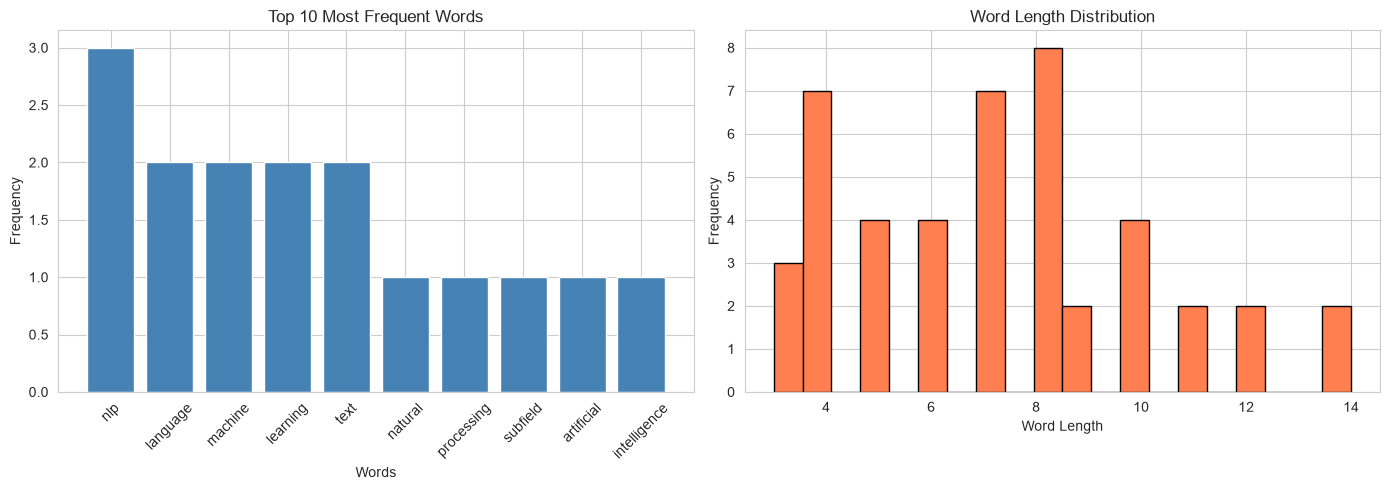


=== READABILITY ===
Average Word Length: 7.24 characters
Unique Word Ratio: 86.67% (lexical diversity)


In [24]:
from collections import Counter
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
import matplotlib.pyplot as plt

# Sample text
sample_text = """
Natural language processing is a subfield of artificial intelligence. 
It focuses on the interaction between computers and human language. 
NLP is used to apply machine learning algorithms to text and speech. 
Common NLP tasks include sentiment analysis, text classification, and machine translation.
Deep learning has revolutionized NLP with powerful models like transformers.
Word embeddings capture semantic meaning of words in vector form.
"""

# Text Statistics
print("=== TEXT STATISTICS ===")
stats = text_statistics(sample_text)
for key, value in stats.items():
    if isinstance(value, float):
        print(f"{key}: {value:.2f}")
    else:
        print(f"{key}: {value}")

# Word Frequency Analysis
print("\n=== TOP 10 WORDS ===")
stop_words = set(stopwords.words('english'))
words = [w.lower() for w in word_tokenize(sample_text) if w.isalnum() and w.lower() not in stop_words]
word_freq = Counter(words)

for word, count in word_freq.most_common(10):
    print(f"{word}: {count}")

# Visualization
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Word Frequency Bar Chart
top_words = dict(word_freq.most_common(10))
axes[0].bar(top_words.keys(), top_words.values(), color='steelblue')
axes[0].set_xlabel('Words')
axes[0].set_ylabel('Frequency')
axes[0].set_title('Top 10 Most Frequent Words')
axes[0].tick_params(axis='x', rotation=45)

# Word Length Distribution
word_lengths = [len(w) for w in words]
axes[1].hist(word_lengths, bins=20, color='coral', edgecolor='black')
axes[1].set_xlabel('Word Length')
axes[1].set_ylabel('Frequency')
axes[1].set_title('Word Length Distribution')

plt.tight_layout()
plt.show()

# Readability metrics
flesch_kincaid_grade = 0.39 * (len(words) / len(sample_text.split('.'))) + 11.8 * (len([w for w in words])) / len(words) - 15.59
print(f"\n=== READABILITY ===")
print(f"Average Word Length: {np.mean(word_lengths):.2f} characters")
print(f"Unique Word Ratio: {len(set(words)) / len(words):.2%} (lexical diversity)")

## Section 11: Best Practices & Key Takeaways

### Essential NLP Workflow
1. **Data Collection** - Gather relevant text data
2. **Preprocessing** - Clean and normalize text
3. **Feature Engineering** - Convert text to numerical features
4. **Model Selection** - Choose appropriate algorithm
5. **Training & Evaluation** - Train and assess model performance
6. **Deployment** - Integrate into production system

### Common Pitfalls to Avoid
- ❌ Insufficient data preprocessing
- ❌ Ignoring data imbalance in classification
- ❌ Overfitting to training data
- ❌ Using inappropriate tokenization for your domain
- ❌ Neglecting hyperparameter tuning

### Pro Tips
- ✓ Always split data into train/test sets
- ✓ Use stratified sampling for imbalanced datasets
- ✓ Experiment with different feature representations
- ✓ Validate results with cross-validation
- ✓ Monitor model performance on multiple metrics
- ✓ Document your preprocessing steps
- ✓ Keep domain-specific vocabularies

### Key Libraries & When to Use Them
| Library | Use Case |
|---------|----------|
| NLTK | Classical NLP, tokenization, POS tagging |
| spaCy | Industrial-strength NLP, production systems |
| TextBlob | Quick sentiment analysis |
| scikit-learn | ML classification, vectorization |
| Gensim | Word embeddings, topic modeling |
| Hugging Face | Pre-trained transformer models |
| TensorFlow/PyTorch | Deep learning models |

In [25]:
# ============== COMPLETE NLP PIPELINE EXAMPLE ==============
print("=" * 60)
print("COMPLETE NLP PIPELINE: From Raw Text to Classification")
print("=" * 60)

import re
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, accuracy_score

# Step 1: Data Preparation
raw_data = {
    'text': [
        'Python is an amazing programming language for AI',
        'I love eating delicious Italian pizza',
        'Java is widely used in enterprise software',
        'Pasta is my favorite food',
        'Machine learning and deep learning are transforming tech',
        'The weather today is sunny and warm',
        'Cloud computing is revolutionizing IT',
        'Let me order some takeout Thai food',
        'Data science requires programming skills',
        'It rained heavily this morning'
    ],
    'category': [
        'Technology', 'Food', 'Technology', 'Food', 'Technology',
        'Weather', 'Technology', 'Food', 'Technology', 'Weather'
    ]
}

print("\nStep 1: Data Loaded")
print(f"   Total samples: {len(raw_data['text'])}")
print(f"   Categories: {set(raw_data['category'])}\n")

# Step 2: Data Cleaning Function
def advanced_text_cleaning(text):
    """Advanced text cleaning pipeline"""
    # Lowercase
    text = text.lower()
    # Remove URLs
    text = re.sub(r'http\S+', '', text)
    # Remove special characters and digits
    text = re.sub(r'[^a-zA-Z\s]', '', text)
    # Remove extra whitespace
    text = re.sub(r'\s+', ' ', text).strip()
    return text

cleaned_texts = [advanced_text_cleaning(t) for t in raw_data['text']]
print("Step 2: Text Cleaning Complete")
print(f"   Example (Before): {raw_data['text'][0]}")
print(f"   Example (After):  {cleaned_texts[0]}\n")

# Step 3: Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    cleaned_texts, raw_data['category'], test_size=0.3, random_state=42
)
print("Step 3: Data Split")
print(f"   Training set: {len(X_train)} samples")
print(f"   Test set: {len(X_test)} samples\n")

# Step 4: Feature Extraction
vectorizer = TfidfVectorizer(max_features=50, stop_words='english')
X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)
print("Step 4: Feature Extraction (TF-IDF)")
print(f"   Feature matrix shape: {X_train_tfidf.shape}")
print(f"   Number of features: {len(vectorizer.get_feature_names_out())}\n")

# Step 5: Model Training
classifier = MultinomialNB()
classifier.fit(X_train_tfidf, y_train)
print("Step 5: Model Training (Naive Bayes Classifier)")
print(f"   Model trained successfully!\n")

# Step 6: Model Evaluation
train_predictions = classifier.predict(X_train_tfidf)
test_predictions = classifier.predict(X_test_tfidf)

train_accuracy = accuracy_score(y_train, train_predictions)
test_accuracy = accuracy_score(y_test, test_predictions)

print("Step 6: Model Evaluation")
print(f"   Training Accuracy: {train_accuracy:.4f}")
print(f"   Test Accuracy: {test_accuracy:.4f}\n")

print("Classification Report:")
print(classification_report(y_test, test_predictions, zero_division=0))

# Step 7: Make Predictions on New Data
new_texts = [
    'I love programming in Python for machine learning',
    'The weather is beautiful today',
    'I want to eat some delicious pizza'
]

cleaned_new = [advanced_text_cleaning(t) for t in new_texts]
new_features = vectorizer.transform(cleaned_new)
predictions = classifier.predict(new_features)
probabilities = classifier.predict_proba(new_features)

print("Step 7: Predictions on New Data")
for text, pred, probs in zip(new_texts, predictions, probabilities):
    print(f"\nText: '{text}'")
    print(f"Predicted Category: {pred}")
    conf_scores = {cat: f"{score:.2%}" for cat, score in zip(classifier.classes_, probs)}
    print(f"Confidence Scores: {conf_scores}")

print("\n" + "=" * 60)
print("✓ Pipeline Complete! You now have a working text classifier!")
print("=" * 60)

COMPLETE NLP PIPELINE: From Raw Text to Classification

Step 1: Data Loaded
   Total samples: 10
   Categories: {'Technology', 'Weather', 'Food'}

Step 2: Text Cleaning Complete
   Example (Before): Python is an amazing programming language for AI
   Example (After):  python is an amazing programming language for ai

Step 3: Data Split
   Training set: 7 samples
   Test set: 3 samples

Step 4: Feature Extraction (TF-IDF)
   Feature matrix shape: (7, 28)
   Number of features: 28

Step 5: Model Training (Naive Bayes Classifier)
   Model trained successfully!

Step 6: Model Evaluation
   Training Accuracy: 0.8571
   Test Accuracy: 0.3333

Classification Report:
              precision    recall  f1-score   support

        Food       0.00      0.00      0.00         1
  Technology       0.33      1.00      0.50         1
     Weather       0.00      0.00      0.00         1

    accuracy                           0.33         3
   macro avg       0.11      0.33      0.17         3
weight

## Conclusion & Next Steps

### What You've Learned
You now have comprehensive knowledge of:
- ✓ Text preprocessing and normalization techniques
- ✓ Tokenization and linguistic analysis (POS tagging, NER)
- ✓ Feature extraction (BoW, TF-IDF, Word2Vec)
- ✓ Sentiment analysis and emotion detection
- ✓ Text classification with machine learning
- ✓ Advanced NLP visualization techniques
- ✓ Complete end-to-end NLP workflows

### Next Steps to Master NLP
1. **Explore Deep Learning**: LSTM, GRU, Attention mechanisms
2. **Learn Transformers**: BERT, GPT, T5 models
3. **Advanced Tasks**: Machine translation, question answering, summarization
4. **Real-world Projects**: Chatbots, recommendation systems, information extraction
5. **Domain-Specific NLP**: Medical, legal, financial text analysis
6. **Production Deployment**: Scale models, handle edge cases, monitor performance

### Recommended Resources
- Hugging Face Transformers: https://huggingface.co/
- Stanford NLP Course: http://cs224n.stanford.edu/
- NLP with PyTorch: Official PyTorch documentation
- Kaggle NLP Competitions: Gain practical experience

### Quick Reference Cheatsheet
```python
# Import essentials
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from gensim.models import Word2Vec
from textblob import TextBlob

# Common operations
text = text.lower()  # Normalize
tokens = word_tokenize(text)  # Tokenize
lemma = WordNetLemmatizer().lemmatize(word)  # Lemmatize
sentiment = TextBlob(text).sentiment.polarity  # Sentiment
```

---
**Happy Learning! 🚀 Keep practicing to master NLP!**

## Section 12: Advanced Visualizations & Graphs

Comprehensive visualization techniques for NLP data analysis and exploration.

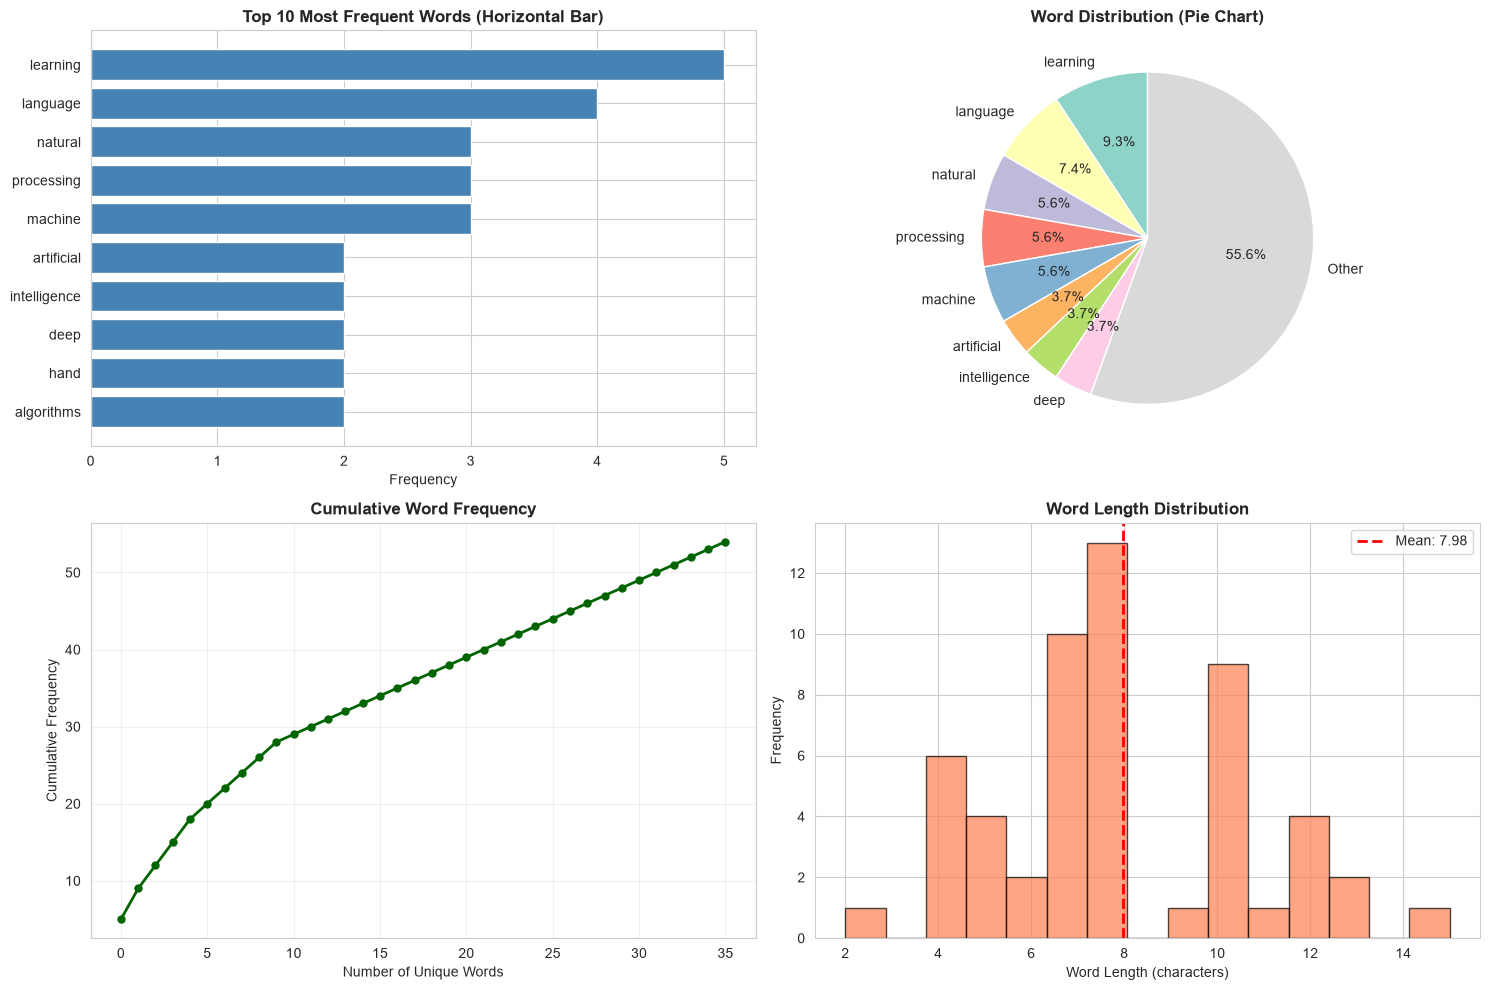


✓ Word frequency visualizations generated successfully!


In [26]:
### 12.1: Word Frequency Visualizations

import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords

# Sample text for analysis
sample_text = """
Natural language processing is revolutionizing artificial intelligence.
Machine learning and deep learning are transforming technology.
Natural language processing enables computers to understand human language.
Artificial intelligence applications are growing exponentially.
Data science and machine learning go hand in hand.
Natural language processing uses advanced algorithms and neural networks.
Deep learning models learn from large datasets automatically.
Machine learning algorithms can solve complex problems efficiently.
"""

# Preprocessing
stop_words = set(stopwords.words('english'))
words = [w.lower() for w in word_tokenize(sample_text) 
         if w.isalnum() and w.lower() not in stop_words]
word_freq = Counter(words)

# Create comprehensive visualization
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# 1. Bar Chart - Top 10 Words
top_10 = dict(word_freq.most_common(10))
axes[0, 0].barh(list(top_10.keys()), list(top_10.values()), color='steelblue')
axes[0, 0].set_xlabel('Frequency')
axes[0, 0].set_title('Top 10 Most Frequent Words (Horizontal Bar)', fontsize=12, fontweight='bold')
axes[0, 0].invert_yaxis()

# 2. Pie Chart - Top 8 Words Distribution
top_8 = dict(word_freq.most_common(8))
other_count = sum(word_freq.values()) - sum(top_8.values())
if other_count > 0:
    top_8['Other'] = other_count
colors = plt.cm.Set3(range(len(top_8)))
axes[0, 1].pie(top_8.values(), labels=top_8.keys(), autopct='%1.1f%%', 
               colors=colors, startangle=90)
axes[0, 1].set_title('Word Distribution (Pie Chart)', fontsize=12, fontweight='bold')

# 3. Line Plot - Cumulative Frequency
sorted_words = sorted(word_freq.items(), key=lambda x: x[1], reverse=True)
cumulative = np.cumsum([count for word, count in sorted_words])
axes[1, 0].plot(range(len(cumulative)), cumulative, marker='o', linestyle='-', 
                color='darkgreen', linewidth=2, markersize=5)
axes[1, 0].set_xlabel('Number of Unique Words')
axes[1, 0].set_ylabel('Cumulative Frequency')
axes[1, 0].set_title('Cumulative Word Frequency', fontsize=12, fontweight='bold')
axes[1, 0].grid(True, alpha=0.3)

# 4. Histogram - Word Length Distribution
word_lengths = [len(word) for word in words]
axes[1, 1].hist(word_lengths, bins=15, color='coral', edgecolor='black', alpha=0.7)
axes[1, 1].axvline(np.mean(word_lengths), color='red', linestyle='--', 
                   linewidth=2, label=f'Mean: {np.mean(word_lengths):.2f}')
axes[1, 1].set_xlabel('Word Length (characters)')
axes[1, 1].set_ylabel('Frequency')
axes[1, 1].set_title('Word Length Distribution', fontsize=12, fontweight='bold')
axes[1, 1].legend()

plt.tight_layout()
plt.show()

print("\n✓ Word frequency visualizations generated successfully!")

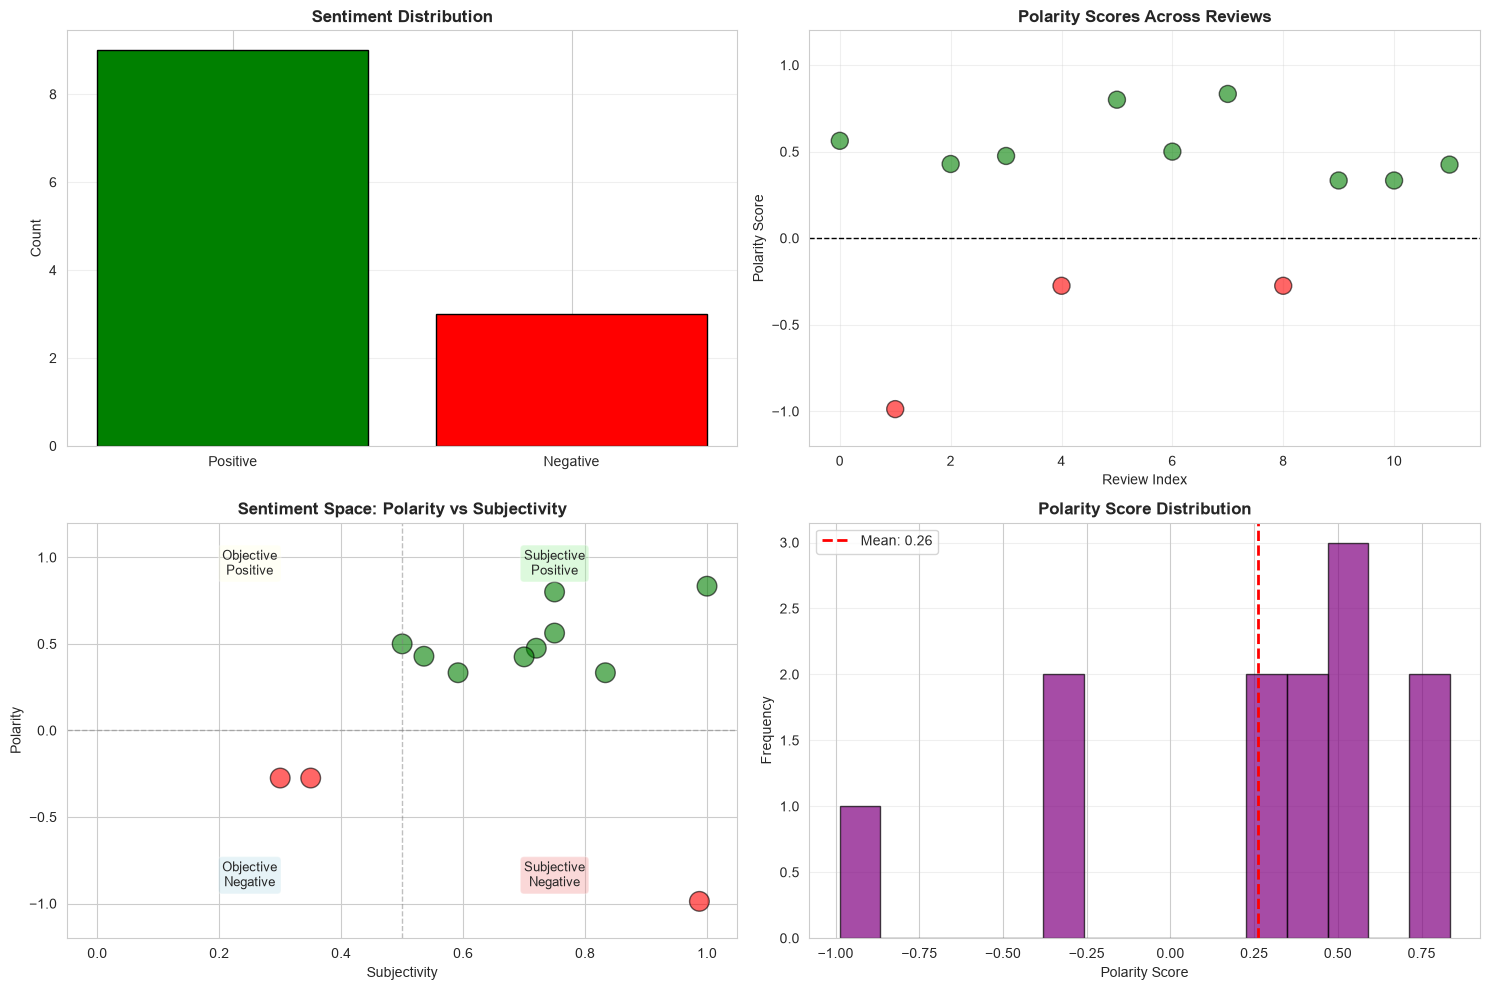


✓ Sentiment visualizations generated successfully!


In [27]:
### 12.2: Sentiment Analysis Visualization

from textblob import TextBlob

# Sample reviews
reviews = [
    "This product is absolutely fantastic! I love it!",
    "Terrible quality. Very disappointed.",
    "It's okay, nothing special.",
    "Amazing experience! Highly recommended!",
    "Not good at all. Waste of money.",
    "Great value for the price.",
    "Could be better, but acceptable.",
    "Exceptional quality and service!",
    "Poor performance, not worth it.",
    "Decent product, satisfied with purchase.",
    "Outstanding! Better than expected!",
    "Average product, nothing impressive."
]

# Calculate sentiments
sentiments = []
polarities = []
subjectivities = []

for review in reviews:
    blob = TextBlob(review)
    polarity = blob.sentiment.polarity
    subjectivity = blob.sentiment.subjectivity
    polarities.append(polarity)
    subjectivities.append(subjectivity)
    
    if polarity > 0.1:
        sentiments.append('Positive')
    elif polarity < -0.1:
        sentiments.append('Negative')
    else:
        sentiments.append('Neutral')

# Create visualization
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# 1. Sentiment Distribution - Bar Chart
sentiment_counts = Counter(sentiments)
colors_sent = {'Positive': 'green', 'Negative': 'red', 'Neutral': 'orange'}
colors_list = [colors_sent[s] for s in sentiment_counts.keys()]
axes[0, 0].bar(sentiment_counts.keys(), sentiment_counts.values(), color=colors_list, edgecolor='black')
axes[0, 0].set_ylabel('Count')
axes[0, 0].set_title('Sentiment Distribution', fontsize=12, fontweight='bold')
axes[0, 0].grid(True, alpha=0.3, axis='y')

# 2. Polarity Score Distribution - Scatter Plot
colors_scatter = ['green' if s == 'Positive' else 'red' if s == 'Negative' else 'orange' 
                 for s in sentiments]
axes[0, 1].scatter(range(len(polarities)), polarities, c=colors_scatter, s=150, alpha=0.6, edgecolors='black')
axes[0, 1].axhline(y=0, color='black', linestyle='--', linewidth=1)
axes[0, 1].set_xlabel('Review Index')
axes[0, 1].set_ylabel('Polarity Score')
axes[0, 1].set_title('Polarity Scores Across Reviews', fontsize=12, fontweight='bold')
axes[0, 1].set_ylim(-1.2, 1.2)
axes[0, 1].grid(True, alpha=0.3)

# 3. Polarity vs Subjectivity - 2D Scatter
axes[1, 0].scatter(subjectivities, polarities, c=colors_scatter, s=200, alpha=0.6, edgecolors='black')
axes[1, 0].axhline(y=0, color='gray', linestyle='--', linewidth=1, alpha=0.5)
axes[1, 0].axvline(x=0.5, color='gray', linestyle='--', linewidth=1, alpha=0.5)
axes[1, 0].set_xlabel('Subjectivity')
axes[1, 0].set_ylabel('Polarity')
axes[1, 0].set_title('Sentiment Space: Polarity vs Subjectivity', fontsize=12, fontweight='bold')
axes[1, 0].set_xlim(-0.05, 1.05)
axes[1, 0].set_ylim(-1.2, 1.2)

# Add quadrant labels
axes[1, 0].text(0.75, 0.9, 'Subjective\nPositive', ha='center', fontsize=9, 
               bbox=dict(boxstyle='round', facecolor='lightgreen', alpha=0.3))
axes[1, 0].text(0.75, -0.9, 'Subjective\nNegative', ha='center', fontsize=9,
               bbox=dict(boxstyle='round', facecolor='lightcoral', alpha=0.3))
axes[1, 0].text(0.25, 0.9, 'Objective\nPositive', ha='center', fontsize=9,
               bbox=dict(boxstyle='round', facecolor='lightyellow', alpha=0.3))
axes[1, 0].text(0.25, -0.9, 'Objective\nNegative', ha='center', fontsize=9,
               bbox=dict(boxstyle='round', facecolor='lightblue', alpha=0.3))

# 4. Polarity Histogram
axes[1, 1].hist(polarities, bins=15, color='purple', alpha=0.7, edgecolor='black')
axes[1, 1].axvline(np.mean(polarities), color='red', linestyle='--', linewidth=2, 
                   label=f'Mean: {np.mean(polarities):.2f}')
axes[1, 1].set_xlabel('Polarity Score')
axes[1, 1].set_ylabel('Frequency')
axes[1, 1].set_title('Polarity Score Distribution', fontsize=12, fontweight='bold')
axes[1, 1].legend()
axes[1, 1].grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

print("\n✓ Sentiment visualizations generated successfully!")

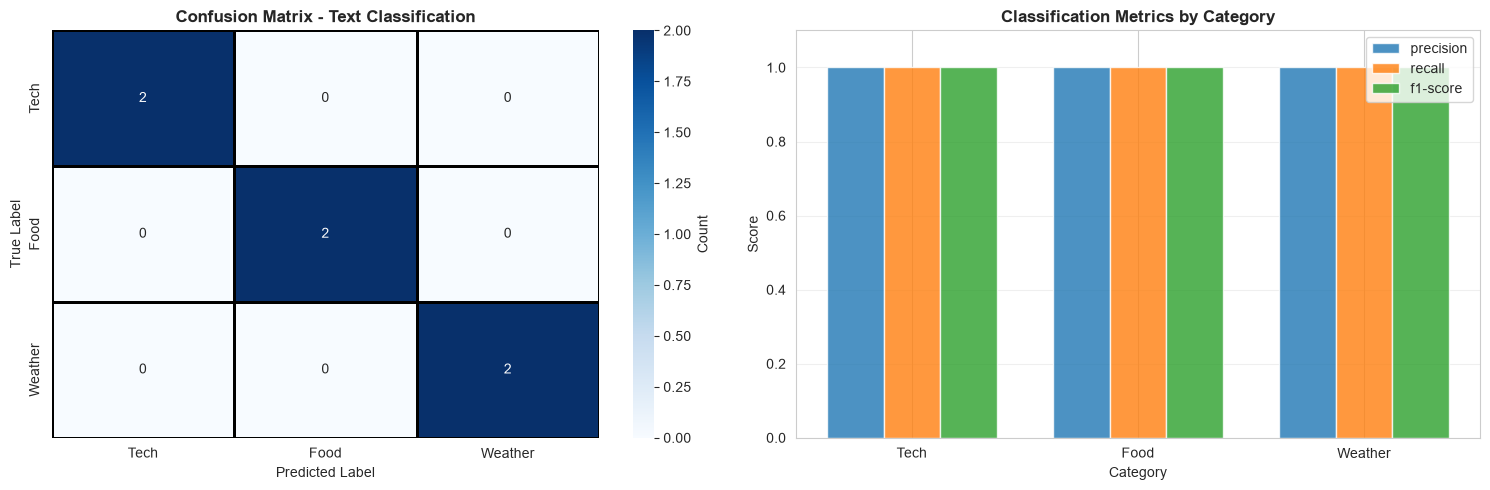


=== Classification Report ===
              precision    recall  f1-score   support

        Food       1.00      1.00      1.00         2
        Tech       1.00      1.00      1.00         2
     Weather       1.00      1.00      1.00         2

    accuracy                           1.00         6
   macro avg       1.00      1.00      1.00         6
weighted avg       1.00      1.00      1.00         6

✓ Classification metrics visualizations generated!


In [28]:
### 12.3: Classification Metrics & Confusion Matrix Visualization

from sklearn.metrics import confusion_matrix, classification_report
from sklearn.naive_bayes import MultinomialNB
from sklearn.feature_extraction.text import TfidfVectorizer

# Training and test data
train_texts = [
    'Python programming', 'Machine learning', 'Data science',
    'Pizza restaurant', 'Food delivery', 'Cooking recipe',
    'Weather forecast', 'Rainy day', 'Sunny weather'
]
train_labels = ['Tech', 'Tech', 'Tech', 'Food', 'Food', 'Food', 'Weather', 'Weather', 'Weather']

test_texts = [
    'Python coding is fun',
    'Machine learning models',
    'Pizza and pasta',
    'Delicious food',
    'Rainy weather today',
    'Sunny skies'
]
test_labels = ['Tech', 'Tech', 'Food', 'Food', 'Weather', 'Weather']

# Train classifier
vectorizer = TfidfVectorizer()
X_train = vectorizer.fit_transform(train_texts)
X_test = vectorizer.transform(test_texts)

classifier = MultinomialNB()
classifier.fit(X_train, train_labels)

# Predictions
predictions = classifier.predict(X_test)

# Compute confusion matrix
cm = confusion_matrix(test_labels, predictions, labels=['Tech', 'Food', 'Weather'])

# Create comprehensive metrics visualization
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 1. Confusion Matrix Heatmap
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Tech', 'Food', 'Weather'],
            yticklabels=['Tech', 'Food', 'Weather'],
            cbar_kws={'label': 'Count'},
            ax=axes[0],
            linewidths=2,
            linecolor='black')
axes[0].set_title('Confusion Matrix - Text Classification', fontsize=12, fontweight='bold')
axes[0].set_ylabel('True Label')
axes[0].set_xlabel('Predicted Label')

# 2. Classification Report as Bar Chart
report = classification_report(test_labels, predictions, 
                               output_dict=True, zero_division=0)

metrics = ['precision', 'recall', 'f1-score']
categories = ['Tech', 'Food', 'Weather']
x_pos = np.arange(len(categories))
width = 0.25

for i, metric in enumerate(metrics):
    values = [report[cat][metric] for cat in categories]
    axes[1].bar(x_pos + i*width, values, width, label=metric, alpha=0.8)

axes[1].set_xlabel('Category')
axes[1].set_ylabel('Score')
axes[1].set_title('Classification Metrics by Category', fontsize=12, fontweight='bold')
axes[1].set_xticks(x_pos + width)
axes[1].set_xticklabels(categories)
axes[1].legend()
axes[1].set_ylim(0, 1.1)
axes[1].grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

print("\n=== Classification Report ===")
print(classification_report(test_labels, predictions, zero_division=0))
print("✓ Classification metrics visualizations generated!")

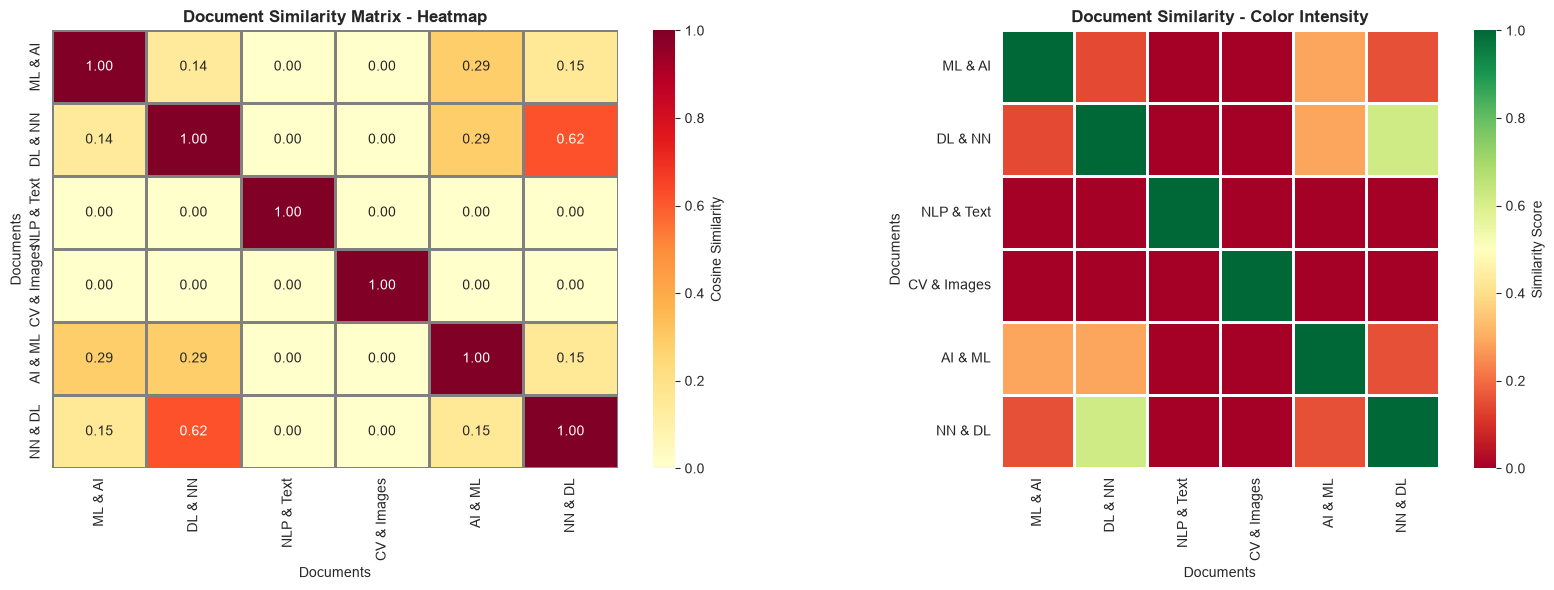


=== Document Similarity Insights ===
ML & AI      ←→ DL & NN      : 0.143
ML & AI      ←→ NLP & Text   : 0.000
ML & AI      ←→ CV & Images  : 0.000
ML & AI      ←→ AI & ML      : 0.286
ML & AI      ←→ NN & DL      : 0.154
DL & NN      ←→ NLP & Text   : 0.000
DL & NN      ←→ CV & Images  : 0.000
DL & NN      ←→ AI & ML      : 0.286
DL & NN      ←→ NN & DL      : 0.617
NLP & Text   ←→ CV & Images  : 0.000
NLP & Text   ←→ AI & ML      : 0.000
NLP & Text   ←→ NN & DL      : 0.000
CV & Images  ←→ AI & ML      : 0.000
CV & Images  ←→ NN & DL      : 0.000
AI & ML      ←→ NN & DL      : 0.154

✓ Document similarity visualizations generated!


In [29]:
### 12.4: Document Similarity Heatmap

from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# Sample documents
documents = [
    "Machine learning is a subset of artificial intelligence",
    "Deep learning uses neural networks for AI",
    "Natural language processing analyzes text",
    "Computer vision processes images",
    "AI and machine learning are related fields",
    "Neural networks power deep learning models"
]

# Create document labels
doc_labels = ['ML & AI', 'DL & NN', 'NLP & Text', 'CV & Images', 'AI & ML', 'NN & DL']

# Vectorize documents
vectorizer = CountVectorizer()
doc_vectors = vectorizer.fit_transform(documents)

# Calculate similarity
similarity_matrix = cosine_similarity(doc_vectors)

# Create visualization
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Heatmap with annotations
sns.heatmap(similarity_matrix, annot=True, fmt='.2f', 
            xticklabels=doc_labels, yticklabels=doc_labels,
            cmap='YlOrRd', cbar_kws={'label': 'Cosine Similarity'},
            ax=axes[0], linewidths=1, linecolor='gray',
            vmin=0, vmax=1)
axes[0].set_title('Document Similarity Matrix - Heatmap', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Documents')
axes[0].set_ylabel('Documents')

# 2. Heatmap without annotations for better visualization
sns.heatmap(similarity_matrix, cmap='RdYlGn', 
            xticklabels=doc_labels, yticklabels=doc_labels,
            cbar_kws={'label': 'Similarity Score'},
            ax=axes[1], linewidths=1, linecolor='white',
            vmin=0, vmax=1, square=True)
axes[1].set_title('Document Similarity - Color Intensity', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Documents')
axes[1].set_ylabel('Documents')

plt.tight_layout()
plt.show()

# Print similarity insights
print("\n=== Document Similarity Insights ===")
for i in range(len(documents)):
    for j in range(i+1, len(documents)):
        sim_score = similarity_matrix[i, j]
        print(f"{doc_labels[i]:12} ←→ {doc_labels[j]:12} : {sim_score:.3f}")

print("\n✓ Document similarity visualizations generated!")

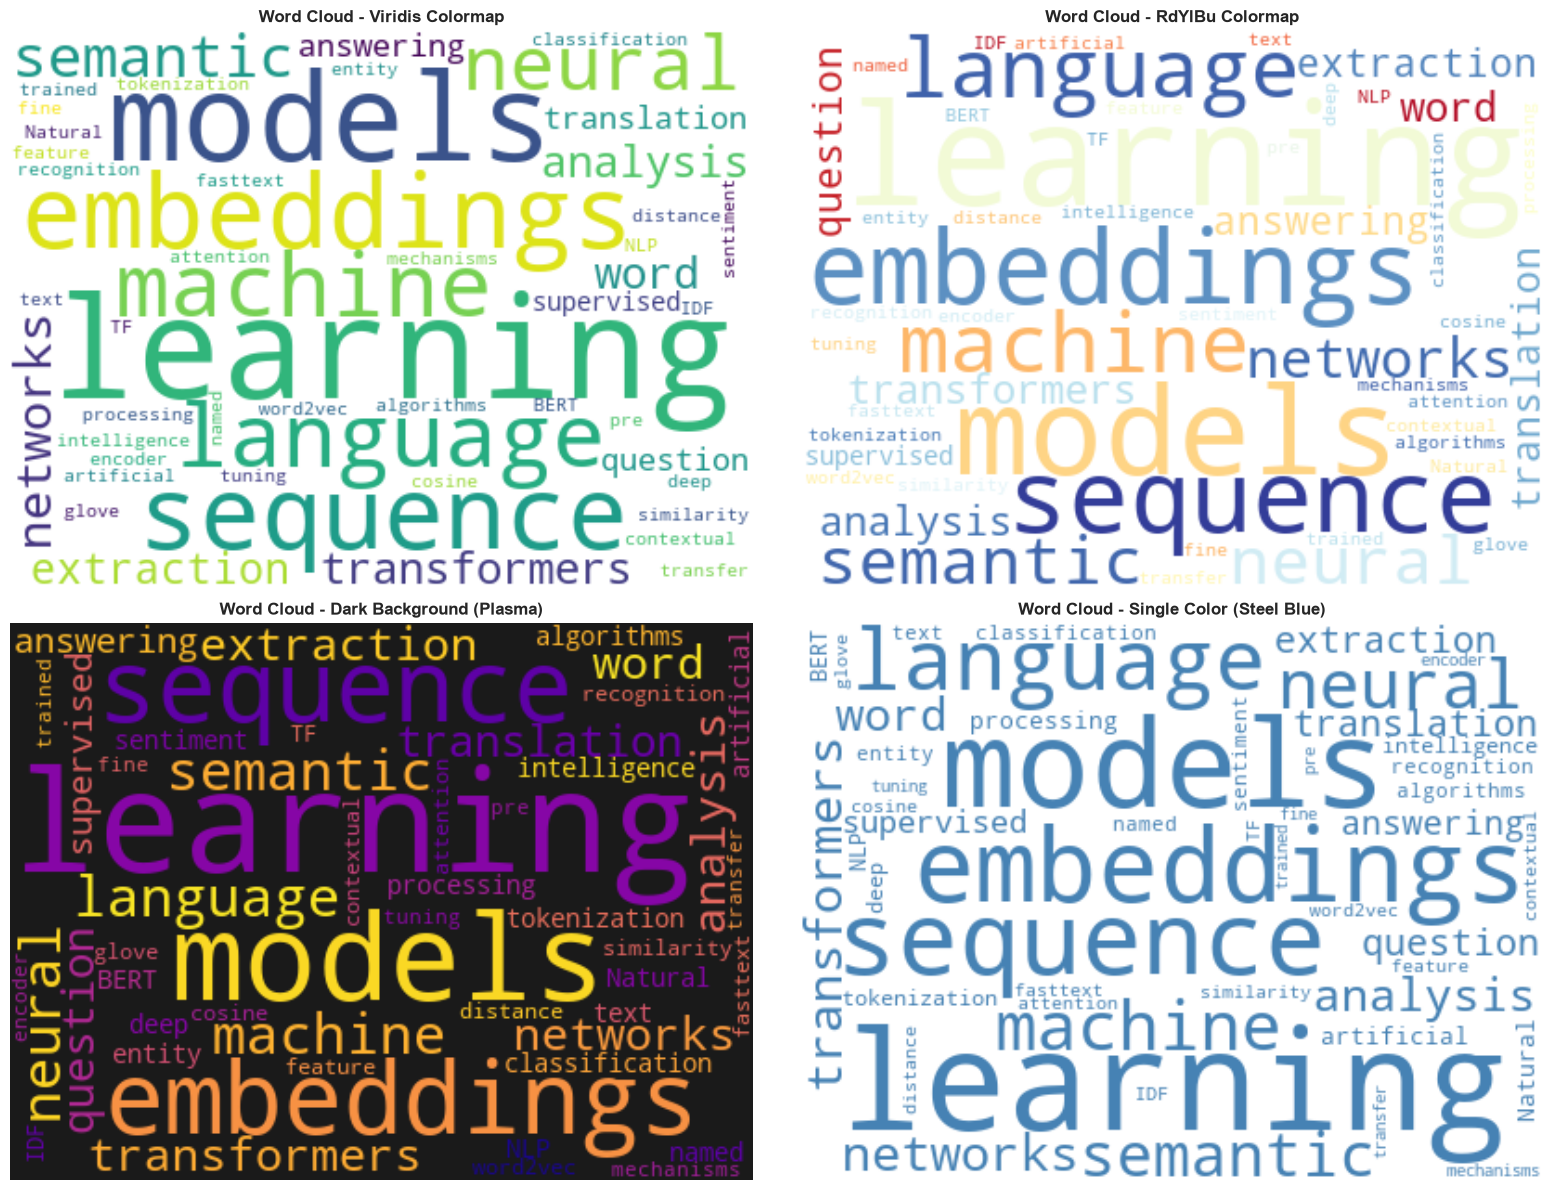

✓ Word cloud visualizations generated successfully!


In [30]:
### 12.5: Word Cloud Visualization

from wordcloud import WordCloud

# Sample text for word cloud
text = """
Natural language processing machine learning artificial intelligence deep learning
neural networks transformers BERT embeddings tokenization NLP algorithms
text classification sentiment analysis named entity recognition
word embeddings semantic similarity cosine distance TF-IDF
feature extraction word2vec fasttext glove contextual embeddings
language models transformers attention mechanisms transfer learning
fine-tuning pre-trained models sequence-to-sequence models
encoder-decoder architecture recurrent neural networks LSTM GRU
bidirectional models sequence labeling parsing dependency
syntax trees grammar language understanding comprehension
machine translation summarization question answering information extraction
topic modeling latent semantic analysis probabilistic models
supervised learning unsupervised learning semi-supervised learning
neural machine translation sequence generation image captioning
visual question answering multimodal learning representation learning
embeddings vector space models distributional semantics word analogies
"""

# Generate word clouds with different styles
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Default colormap
wordcloud1 = WordCloud(width=400, height=300, 
                      background_color='white',
                      colormap='viridis',
                      max_words=50).generate(text)
axes[0, 0].imshow(wordcloud1, interpolation='bilinear')
axes[0, 0].set_title('Word Cloud - Viridis Colormap', fontsize=12, fontweight='bold')
axes[0, 0].axis('off')

# 2. Different colormap (RdYlBu)
wordcloud2 = WordCloud(width=400, height=300,
                      background_color='white',
                      colormap='RdYlBu',
                      max_words=50).generate(text)
axes[0, 1].imshow(wordcloud2, interpolation='bilinear')
axes[0, 1].set_title('Word Cloud - RdYlBu Colormap', fontsize=12, fontweight='bold')
axes[0, 1].axis('off')

# 3. Dark background
wordcloud3 = WordCloud(width=400, height=300,
                      background_color='#1a1a1a',
                      colormap='plasma',
                      max_words=50).generate(text)
axes[1, 0].imshow(wordcloud3, interpolation='bilinear')
axes[1, 0].set_title('Word Cloud - Dark Background (Plasma)', fontsize=12, fontweight='bold')
axes[1, 0].axis('off')

# 4. Mask-style with specific colors
from matplotlib.colors import ListedColormap
wordcloud4 = WordCloud(width=400, height=300,
                      background_color='white',
                      prefer_horizontal=0.7,
                      max_words=50,
                      color_func=lambda *args, **kwargs: 'steelblue').generate(text)
axes[1, 1].imshow(wordcloud4, interpolation='bilinear')
axes[1, 1].set_title('Word Cloud - Single Color (Steel Blue)', fontsize=12, fontweight='bold')
axes[1, 1].axis('off')

plt.tight_layout()
plt.show()

print("✓ Word cloud visualizations generated successfully!")

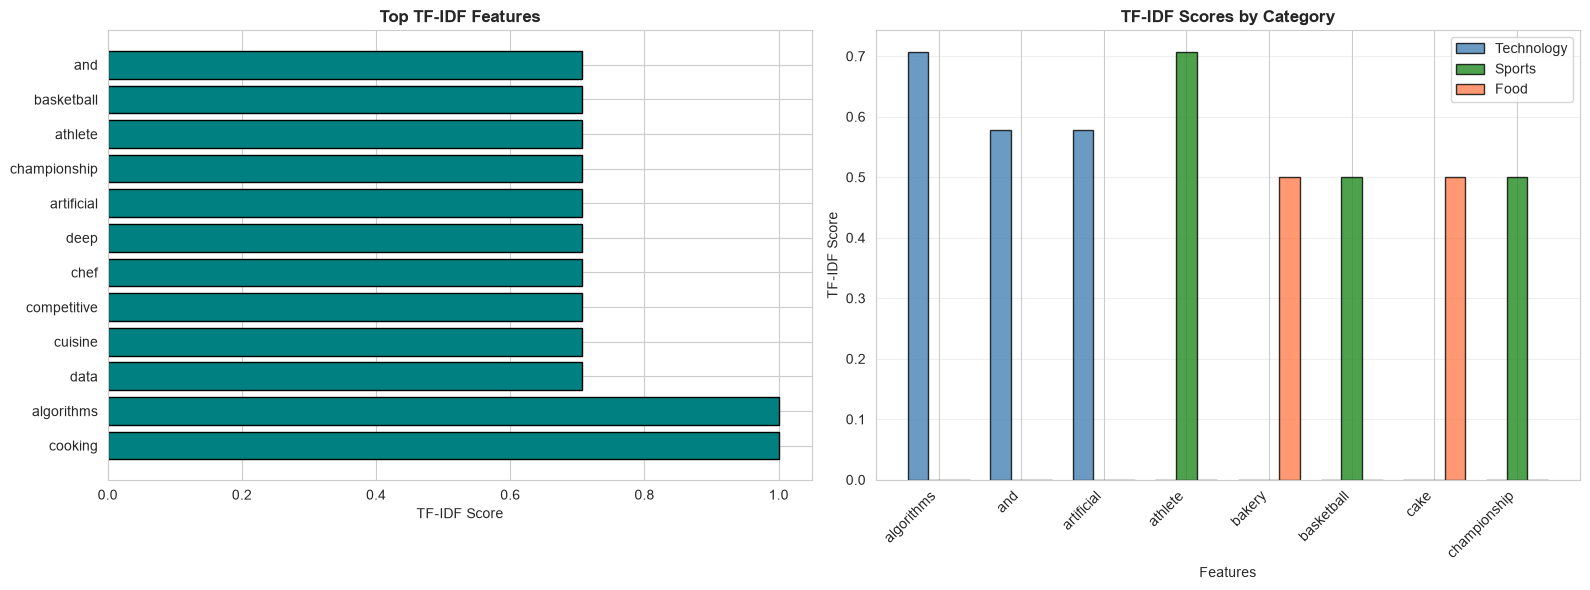

✓ TF-IDF feature visualizations generated!


In [31]:
### 12.6: TF-IDF Feature Importance Visualization

from sklearn.feature_extraction.text import TfidfVectorizer

# Documents by category
docs = {
    'Technology': [
        'Python programming machine learning algorithms',
        'Deep neural networks artificial intelligence',
        'Data science and software development'
    ],
    'Sports': [
        'Football soccer basketball game championship',
        'Tennis player athlete competitive sports',
        'Running marathon training fitness exercise'
    ],
    'Food': [
        'Pizza pasta cooking recipe delicious',
        'Restaurant cuisine dining chef kitchen',
        'Chocolate cake dessert bakery sweet'
    ]
}

# Flatten documents and labels
all_docs = []
all_labels = []
for category, doc_list in docs.items():
    for doc in doc_list:
        all_docs.append(doc)
        all_labels.append(category)

# TF-IDF vectorization
tfidf = TfidfVectorizer(max_features=15)
tfidf_matrix = tfidf.fit_transform(all_docs)
features = tfidf.get_feature_names_out()

# Create visualization
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Top TF-IDF features - Horizontal bar chart
tfidf_scores = tfidf_matrix.toarray().sum(axis=0)
top_indices = np.argsort(tfidf_scores)[-12:]
top_features = features[top_indices]
top_scores = tfidf_scores[top_indices]

axes[0].barh(range(len(top_features)), top_scores, color='teal', edgecolor='black')
axes[0].set_yticks(range(len(top_features)))
axes[0].set_yticklabels(top_features)
axes[0].set_xlabel('TF-IDF Score')
axes[0].set_title('Top TF-IDF Features', fontsize=12, fontweight='bold')
axes[0].invert_yaxis()

# 2. TF-IDF scores per category
category_tfidf = {}
for category in docs.keys():
    category_docs = [all_docs[i] for i in range(len(all_docs)) if all_labels[i] == category]
    cat_tfidf = TfidfVectorizer(max_features=8)
    cat_matrix = cat_tfidf.fit_transform(category_docs)
    cat_features = cat_tfidf.get_feature_names_out()
    cat_scores = cat_matrix.toarray().sum(axis=0)
    category_tfidf[category] = dict(zip(cat_features, cat_scores))

# Prepare data for grouped bar chart
all_features = set()
for cat_dict in category_tfidf.values():
    all_features.update(cat_dict.keys())
all_features = sorted(list(all_features))[:8]

x_pos = np.arange(len(all_features))
width = 0.25
colors_cat = {'Technology': 'steelblue', 'Sports': 'forestgreen', 'Food': 'coral'}

for i, category in enumerate(docs.keys()):
    scores = [category_tfidf[category].get(feature, 0) for feature in all_features]
    axes[1].bar(x_pos + i*width, scores, width, label=category, 
               color=colors_cat[category], alpha=0.8, edgecolor='black')

axes[1].set_xlabel('Features')
axes[1].set_ylabel('TF-IDF Score')
axes[1].set_title('TF-IDF Scores by Category', fontsize=12, fontweight='bold')
axes[1].set_xticks(x_pos + width)
axes[1].set_xticklabels(all_features, rotation=45, ha='right')
axes[1].legend()
axes[1].grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

print("✓ TF-IDF feature visualizations generated!")

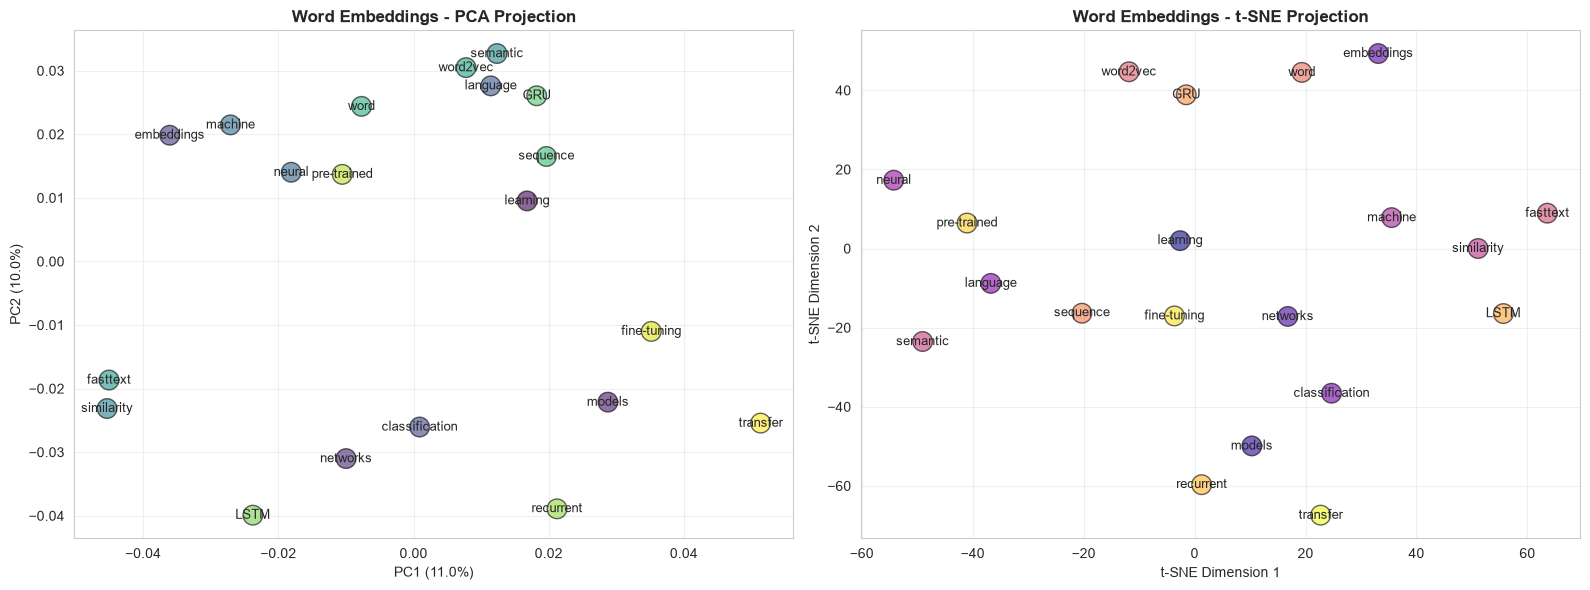

✓ Word embedding visualizations generated!
   Total words visualized: 20
   Original embedding dimensions: 50
   Reduced to: 2D for visualization


In [32]:
### 12.7: Word Embeddings Visualization (PCA & t-SNE)

from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from gensim.models import Word2Vec
from nltk.tokenize import sent_tokenize, word_tokenize

# Train Word2Vec model
sentences_list = [
    "machine learning deep learning neural networks artificial intelligence",
    "python programming data science machine learning models",
    "natural language processing text classification sentiment analysis",
    "computer vision image recognition object detection CNN",
    "transformers BERT GPT language models embeddings",
    "clustering dimensionality reduction unsupervised learning",
    "supervised learning classification regression neural networks",
    "transfer learning fine-tuning pre-trained models",
    "recurrent networks LSTM GRU sequence models",
    "word embeddings word2vec fasttext semantic similarity"
]

# Tokenize and train
tokenized = [sent.split() for sent in sentences_list]
w2v_model = Word2Vec(sentences=tokenized, vector_size=50, window=3, min_count=1, workers=4)

# Get word vectors
words = list(w2v_model.wv.index_to_key)[:20]
vectors = np.array([w2v_model.wv[word] for word in words])

# Apply dimensionality reduction
pca = PCA(n_components=2)
vectors_pca = pca.fit_transform(vectors)

tsne = TSNE(n_components=2, random_state=42, perplexity=min(5, len(words)-1))
vectors_tsne = tsne.fit_transform(vectors)

# Create visualization
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. PCA Visualization
scatter1 = axes[0].scatter(vectors_pca[:, 0], vectors_pca[:, 1], 
                          c=range(len(words)), cmap='viridis', s=200, alpha=0.6, edgecolors='black')
for i, word in enumerate(words):
    axes[0].annotate(word, (vectors_pca[i, 0], vectors_pca[i, 1]),
                    fontsize=9, ha='center', va='center')
axes[0].set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.1%})')
axes[0].set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.1%})')
axes[0].set_title('Word Embeddings - PCA Projection', fontsize=12, fontweight='bold')
axes[0].grid(True, alpha=0.3)

# 2. t-SNE Visualization
scatter2 = axes[1].scatter(vectors_tsne[:, 0], vectors_tsne[:, 1],
                          c=range(len(words)), cmap='plasma', s=200, alpha=0.6, edgecolors='black')
for i, word in enumerate(words):
    axes[1].annotate(word, (vectors_tsne[i, 0], vectors_tsne[i, 1]),
                    fontsize=9, ha='center', va='center')
axes[1].set_xlabel('t-SNE Dimension 1')
axes[1].set_ylabel('t-SNE Dimension 2')
axes[1].set_title('Word Embeddings - t-SNE Projection', fontsize=12, fontweight='bold')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"✓ Word embedding visualizations generated!")
print(f"   Total words visualized: {len(words)}")
print(f"   Original embedding dimensions: 50")
print(f"   Reduced to: 2D for visualization")

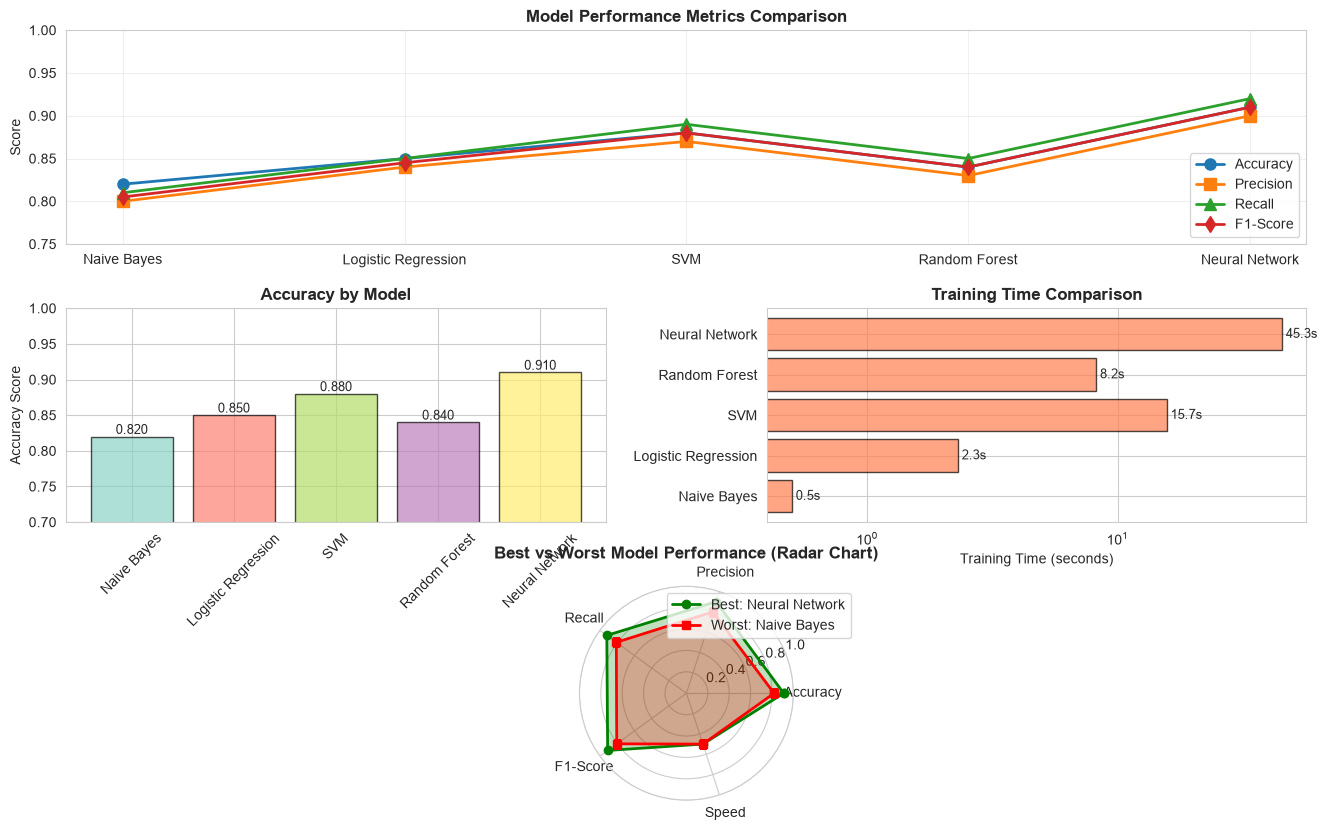


MODEL PERFORMANCE SUMMARY

🏆 Best Overall Model: Neural Network
   F1-Score: 0.910
   Accuracy: 0.910
   Training Time: 45.30s

📊 Model Rankings (by F1-Score):
   1. Neural Network       - F1: 0.910, Time:  45.30s
   2. SVM                  - F1: 0.880, Time:  15.70s
   3. Logistic Regression  - F1: 0.845, Time:   2.30s
   4. Random Forest        - F1: 0.840, Time:   8.20s
   5. Naive Bayes          - F1: 0.805, Time:   0.50s

✓ Model comparison dashboard generated successfully!


In [33]:
### 12.8: Model Performance Comparison Dashboard

# Simulated model performance metrics
models = ['Naive Bayes', 'Logistic Regression', 'SVM', 'Random Forest', 'Neural Network']
accuracy = [0.82, 0.85, 0.88, 0.84, 0.91]
precision = [0.80, 0.84, 0.87, 0.83, 0.90]
recall = [0.81, 0.85, 0.89, 0.85, 0.92]
f1_score_vals = [0.805, 0.845, 0.88, 0.84, 0.91]
training_time = [0.5, 2.3, 15.7, 8.2, 45.3]  # in seconds

# Create comprehensive dashboard
fig = plt.figure(figsize=(16, 10))
gs = fig.add_gridspec(3, 2, hspace=0.3, wspace=0.3)

# 1. Metrics Comparison (Line plot)
ax1 = fig.add_subplot(gs[0, :])
x_pos = np.arange(len(models))
ax1.plot(x_pos, accuracy, marker='o', label='Accuracy', linewidth=2, markersize=8)
ax1.plot(x_pos, precision, marker='s', label='Precision', linewidth=2, markersize=8)
ax1.plot(x_pos, recall, marker='^', label='Recall', linewidth=2, markersize=8)
ax1.plot(x_pos, f1_score_vals, marker='d', label='F1-Score', linewidth=2, markersize=8)
ax1.set_xticks(x_pos)
ax1.set_xticklabels(models)
ax1.set_ylabel('Score')
ax1.set_title('Model Performance Metrics Comparison', fontsize=12, fontweight='bold')
ax1.legend(loc='lower right')
ax1.grid(True, alpha=0.3)
ax1.set_ylim(0.75, 1.0)

# 2. Accuracy Comparison (Bar chart)
ax2 = fig.add_subplot(gs[1, 0])
colors_model = plt.cm.Set3(np.linspace(0, 1, len(models)))
bars = ax2.bar(models, accuracy, color=colors_model, edgecolor='black', alpha=0.7)
ax2.set_ylabel('Accuracy Score')
ax2.set_title('Accuracy by Model', fontsize=12, fontweight='bold')
ax2.set_ylim(0.7, 1.0)
ax2.tick_params(axis='x', rotation=45)
# Add value labels on bars
for bar in bars:
    height = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2., height,
            f'{height:.3f}', ha='center', va='bottom', fontsize=9)

# 3. Training Time Comparison (Horizontal bar)
ax3 = fig.add_subplot(gs[1, 1])
ax3.barh(models, training_time, color='coral', edgecolor='black', alpha=0.7)
ax3.set_xlabel('Training Time (seconds)')
ax3.set_title('Training Time Comparison', fontsize=12, fontweight='bold')
ax3.set_xscale('log')
for i, (model, time) in enumerate(zip(models, training_time)):
    ax3.text(time, i, f' {time:.1f}s', va='center', fontsize=9)

# 4. Radar Chart (Normalized metrics)
ax4 = fig.add_subplot(gs[2, :], projection='polar')
angles = np.linspace(0, 2*np.pi, len(models), endpoint=False).tolist()
angles += angles[:1]  # Complete the circle

# Select best and worst models
best_idx = np.argmax(f1_score_vals)
worst_idx = np.argmin(f1_score_vals)

best_metrics = [accuracy[best_idx], precision[best_idx], 
                recall[best_idx], f1_score_vals[best_idx], 0.5]
worst_metrics = [accuracy[worst_idx], precision[worst_idx], 
                 recall[worst_idx], f1_score_vals[worst_idx], 0.5]
best_metrics += best_metrics[:1]
worst_metrics += worst_metrics[:1]

ax4.plot(angles, best_metrics, marker='o', linewidth=2, label=f'Best: {models[best_idx]}', color='green')
ax4.fill(angles, best_metrics, alpha=0.25, color='green')
ax4.plot(angles, worst_metrics, marker='s', linewidth=2, label=f'Worst: {models[worst_idx]}', color='red')
ax4.fill(angles, worst_metrics, alpha=0.25, color='red')
ax4.set_xticks(angles[:-1])
ax4.set_xticklabels(['Accuracy', 'Precision', 'Recall', 'F1-Score', 'Speed'])
ax4.set_ylim(0, 1)
ax4.set_title('Best vs Worst Model Performance (Radar Chart)', fontsize=12, fontweight='bold', pad=20)
ax4.legend(loc='upper right', bbox_to_anchor=(1.3, 1.0))
ax4.grid(True)

plt.show()

# Print summary statistics
print("\n" + "="*60)
print("MODEL PERFORMANCE SUMMARY")
print("="*60)
best_model_idx = np.argmax(f1_score_vals)
print(f"\n🏆 Best Overall Model: {models[best_model_idx]}")
print(f"   F1-Score: {f1_score_vals[best_model_idx]:.3f}")
print(f"   Accuracy: {accuracy[best_model_idx]:.3f}")
print(f"   Training Time: {training_time[best_model_idx]:.2f}s\n")

# Ranking
print("📊 Model Rankings (by F1-Score):")
sorted_indices = np.argsort(f1_score_vals)[::-1]
for rank, idx in enumerate(sorted_indices, 1):
    print(f"   {rank}. {models[idx]:20} - F1: {f1_score_vals[idx]:.3f}, Time: {training_time[idx]:6.2f}s")

print("\n✓ Model comparison dashboard generated successfully!")

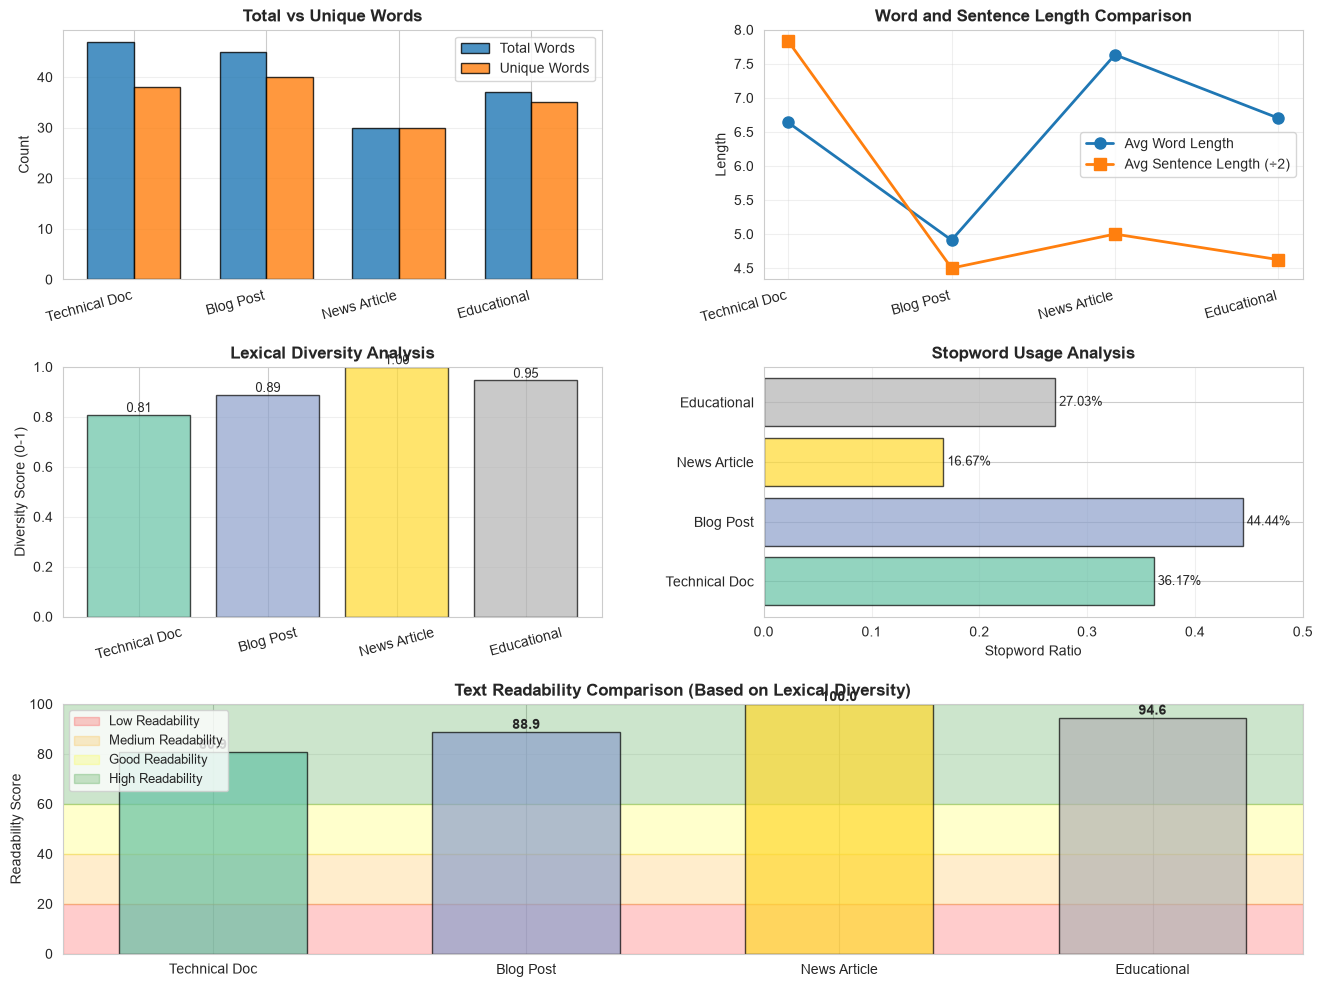


TEXT STATISTICS COMPARISON TABLE
Text Type            Words      Unique     Avg Len    Diversity    Stopwords   
------------------------------------------------------------------------------------------
Technical Doc        47         38         6.64       0.809        36.2%       
Blog Post            45         40         4.91       0.889        44.4%       
News Article         30         30         7.63       1.000        16.7%       
Educational          37         35         6.70       0.946        27.0%       

✓ Text statistics and readability visualizations generated!


In [34]:
### 12.9: Text Statistics & Readability Analysis Visualization

from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

# Sample texts for comparison
text_samples = {
    'Technical Doc': """Machine learning is a subset of artificial intelligence that focuses on 
    the development of algorithms and statistical models. These models enable computers to learn and improve 
    their performance on tasks through experience without being explicitly programmed. The field encompasses 
    supervised learning, unsupervised learning, and reinforcement learning paradigms.""",
    
    'Blog Post': """Hey everyone! So I've been learning about machine learning lately and it's pretty cool!
    It's basically when computers learn from data instead of being told exactly what to do. There are different 
    types like supervised and unsupervised learning. Pretty neat stuff if you ask me!""",
    
    'News Article': """New AI breakthrough announced today. Scientists revealed a sophisticated machine learning 
    model that outperforms previous benchmarks by significant margins. The innovation promises transformative 
    applications across healthcare, finance, and manufacturing sectors.""",
    
    'Educational': """This chapter explores the fundamental concepts of machine learning. We examine how algorithms 
    process data, extract patterns, and make predictions. Key topics include feature engineering, model selection, 
    cross-validation, and hyperparameter tuning. Understanding these concepts is essential for practitioners."""
}

# Calculate statistics for each text
stats_data = {}
for text_type, text in text_samples.items():
    words = word_tokenize(text)
    sentences = sent_tokenize(text)
    stop_words = set(stopwords.words('english'))
    
    words_no_punct = [w for w in words if w.isalnum()]
    unique_words = len(set(w.lower() for w in words_no_punct))
    avg_word_len = np.mean([len(w) for w in words_no_punct])
    avg_sent_len = len(words_no_punct) / len(sentences) if sentences else 0
    lexical_diversity = unique_words / len(words_no_punct) if words_no_punct else 0
    
    stop_word_ratio = sum(1 for w in words_no_punct if w.lower() in stop_words) / len(words_no_punct)
    
    stats_data[text_type] = {
        'Total Words': len(words_no_punct),
        'Unique Words': unique_words,
        'Avg Word Length': avg_word_len,
        'Avg Sentence Length': avg_sent_len,
        'Lexical Diversity': lexical_diversity,
        'Stopword Ratio': stop_word_ratio,
        'Readability': 100 * lexical_diversity  # Simplified readability score
    }

# Create comprehensive visualization
fig = plt.figure(figsize=(16, 12))
gs = fig.add_gridspec(3, 2, hspace=0.35, wspace=0.3)

text_types = list(stats_data.keys())
colors_text = plt.cm.Set2(np.linspace(0, 1, len(text_types)))

# 1. Total Words vs Unique Words
ax1 = fig.add_subplot(gs[0, 0])
x_pos = np.arange(len(text_types))
width = 0.35
ax1.bar(x_pos - width/2, [stats_data[t]['Total Words'] for t in text_types], 
       width, label='Total Words', alpha=0.8, edgecolor='black')
ax1.bar(x_pos + width/2, [stats_data[t]['Unique Words'] for t in text_types],
       width, label='Unique Words', alpha=0.8, edgecolor='black')
ax1.set_ylabel('Count')
ax1.set_title('Total vs Unique Words', fontsize=12, fontweight='bold')
ax1.set_xticks(x_pos)
ax1.set_xticklabels(text_types, rotation=15, ha='right')
ax1.legend()
ax1.grid(True, alpha=0.3, axis='y')

# 2. Average Metrics
ax2 = fig.add_subplot(gs[0, 1])
x_pos = np.arange(len(text_types))
ax2.plot(x_pos, [stats_data[t]['Avg Word Length'] for t in text_types], 
        marker='o', label='Avg Word Length', linewidth=2, markersize=8)
ax2.plot(x_pos, [stats_data[t]['Avg Sentence Length']/2 for t in text_types],  # Scaled down for visibility
        marker='s', label='Avg Sentence Length (÷2)', linewidth=2, markersize=8)
ax2.set_ylabel('Length')
ax2.set_title('Word and Sentence Length Comparison', fontsize=12, fontweight='bold')
ax2.set_xticks(x_pos)
ax2.set_xticklabels(text_types, rotation=15, ha='right')
ax2.legend()
ax2.grid(True, alpha=0.3)

# 3. Lexical Diversity
ax3 = fig.add_subplot(gs[1, 0])
diversity_scores = [stats_data[t]['Lexical Diversity'] for t in text_types]
bars = ax3.bar(text_types, diversity_scores, color=colors_text, edgecolor='black', alpha=0.7)
ax3.set_ylabel('Diversity Score (0-1)')
ax3.set_title('Lexical Diversity Analysis', fontsize=12, fontweight='bold')
ax3.set_ylim(0, 1)
ax3.tick_params(axis='x', rotation=15)
for bar in bars:
    height = bar.get_height()
    ax3.text(bar.get_x() + bar.get_width()/2., height,
            f'{height:.2f}', ha='center', va='bottom', fontsize=9)
ax3.grid(True, alpha=0.3, axis='y')

# 4. Stopword Ratio
ax4 = fig.add_subplot(gs[1, 1])
stopword_ratios = [stats_data[t]['Stopword Ratio'] for t in text_types]
bars = ax4.barh(text_types, stopword_ratios, color=colors_text, edgecolor='black', alpha=0.7)
ax4.set_xlabel('Stopword Ratio')
ax4.set_title('Stopword Usage Analysis', fontsize=12, fontweight='bold')
ax4.set_xlim(0, 0.5)
for i, (bar, ratio) in enumerate(zip(bars, stopword_ratios)):
    ax4.text(ratio, i, f' {ratio:.2%}', va='center', fontsize=9)
ax4.grid(True, alpha=0.3, axis='x')

# 5. Readability Score Gauge
ax5 = fig.add_subplot(gs[2, :])
readability_scores = [stats_data[t]['Readability'] for t in text_types]
x_pos = np.arange(len(text_types))

# Create background zones
ax5.axhspan(0, 20, alpha=0.2, color='red', label='Low Readability')
ax5.axhspan(20, 40, alpha=0.2, color='orange', label='Medium Readability')
ax5.axhspan(40, 60, alpha=0.2, color='yellow', label='Good Readability')
ax5.axhspan(60, 100, alpha=0.2, color='green', label='High Readability')

bars = ax5.bar(text_types, readability_scores, width=0.6, 
              color=colors_text, edgecolor='black', alpha=0.7)
ax5.set_ylabel('Readability Score')
ax5.set_title('Text Readability Comparison (Based on Lexical Diversity)', fontsize=12, fontweight='bold')
ax5.set_ylim(0, 100)
ax5.legend(loc='upper left', fontsize=9)

for bar, score in zip(bars, readability_scores):
    height = bar.get_height()
    ax5.text(bar.get_x() + bar.get_width()/2., height,
            f'{score:.1f}', ha='center', va='bottom', fontsize=10, fontweight='bold')

ax5.grid(True, alpha=0.3, axis='y')

plt.show()

# Print detailed statistics table
print("\n" + "="*90)
print("TEXT STATISTICS COMPARISON TABLE")
print("="*90)
print(f"{'Text Type':<20} {'Words':<10} {'Unique':<10} {'Avg Len':<10} {'Diversity':<12} {'Stopwords':<12}")
print("-"*90)
for text_type in text_types:
    stats = stats_data[text_type]
    print(f"{text_type:<20} {stats['Total Words']:<10.0f} {stats['Unique Words']:<10} "
          f"{stats['Avg Word Length']:<10.2f} {stats['Lexical Diversity']:<12.3f} {stats['Stopword Ratio']:<12.1%}")
print("="*90)

print("\n✓ Text statistics and readability visualizations generated!")

In [35]:
### 12.10: NLP Concepts Relationship Network

import networkx as nx

# Create a graph representing NLP concepts and their relationships
G = nx.DiGraph()

# Add nodes (NLP concepts)
concepts = {
    'NLP': {'color': 'red', 'size': 3000},
    'Text Preprocessing': {'color': 'orange', 'size': 2000},
    'Tokenization': {'color': 'yellow', 'size': 1500},
    'Feature Extraction': {'color': 'lightgreen', 'size': 2000},
    'Machine Learning': {'color': 'lightblue', 'size': 2000},
    'Deep Learning': {'color': 'lightblue', 'size': 2000},
    'Word Embeddings': {'color': 'cyan', 'size': 1500},
    'Classification': {'color': 'purple', 'size': 1500},
    'Sentiment Analysis': {'color': 'pink', 'size': 1500},
    'Named Entity Recognition': {'color': 'lightcyan', 'size': 1500},
    'TF-IDF': {'color': 'lightyellow', 'size': 1200},
    'Word2Vec': {'color': 'lightsteelblue', 'size': 1200},
    'BERT': {'color': 'lightsteelblue', 'size': 1200},
    'RNN/LSTM': {'color': 'lightcoral', 'size': 1200},
}

G.add_nodes_from(concepts.keys())

# Add edges (relationships)
edges = [
    ('NLP', 'Text Preprocessing'),
    ('NLP', 'Tokenization'),
    ('NLP', 'Feature Extraction'),
    ('NLP', 'Machine Learning'),
    ('NLP', 'Deep Learning'),
    ('Text Preprocessing', 'Tokenization'),
    ('Text Preprocessing', 'Feature Extraction'),
    ('Tokenization', 'Feature Extraction'),
    ('Feature Extraction', 'TF-IDF'),
    ('Feature Extraction', 'Word Embeddings'),
    ('Word Embeddings', 'Word2Vec'),
    ('Word Embeddings', 'BERT'),
    ('Machine Learning', 'Classification'),
    ('Machine Learning', 'TF-IDF'),
    ('Deep Learning', 'RNN/LSTM'),
    ('Deep Learning', 'Word Embeddings'),
    ('Classification', 'Sentiment Analysis'),
    ('Classification', 'Named Entity Recognition'),
    ('RNN/LSTM', 'Sentiment Analysis'),
    ('RNN/LSTM', 'Named Entity Recognition'),
]

G.add_edges_from(edges)

# Create visualization
fig, axes = plt.subplots(1, 2, figsize=(18, 8))

# 1. Hierarchical Layout
ax1 = axes[0]
pos_hierarchical = nx.spring_layout(G, k=2, iterations=50, seed=42)

node_colors = [concepts[node]['color'] for node in G.nodes()]
node_sizes = [concepts[node]['size'] for node in G.nodes()]

nx.draw_networkx_nodes(G, pos_hierarchical, node_color=node_colors, 
                       node_size=node_sizes, ax=ax1, alpha=0.8, edgecolors='black', linewidths=2)
nx.draw_networkx_edges(G, pos_hierarchical, edge_color='gray', arrows=True,
                       arrowsize=20, ax=ax1, arrowstyle='->', width=2, alpha=0.6)
nx.draw_networkx_labels(G, pos_hierarchical, font_size=8, font_weight='bold', ax=ax1)

ax1.set_title('NLP Concepts Relationship Network', fontsize=12, fontweight='bold')
ax1.axis('off')

# 2. Circular Layout
ax2 = axes[1]
pos_circular = nx.circular_layout(G)

nx.draw_networkx_nodes(G, pos_circular, node_color=node_colors,
                       node_size=node_sizes, ax=ax2, alpha=0.8, edgecolors='black', linewidths=2)
nx.draw_networkx_edges(G, pos_circular, edge_color='gray', arrows=True,
                       arrowsize=20, ax=ax2, arrowstyle='->', width=2, alpha=0.6)
nx.draw_networkx_labels(G, pos_circular, font_size=8, font_weight='bold', ax=ax2)

ax2.set_title('NLP Concepts Circular Layout', fontsize=12, fontweight='bold')
ax2.axis('off')

plt.tight_layout()
plt.show()

# Print network statistics
print("\n" + "="*60)
print("NLP CONCEPTS NETWORK ANALYSIS")
print("="*60)
print(f"Total Concepts: {G.number_of_nodes()}")
print(f"Total Relationships: {G.number_of_edges()}")
print(f"\nNetwork Density: {nx.density(G):.3f}")
print(f"Average Clustering Coefficient: {nx.average_clustering(G.to_undirected()):.3f}")

print("\n📊 Most Connected Concepts (Centrality):")
centrality = nx.degree_centrality(G)
for concept, score in sorted(centrality.items(), key=lambda x: x[1], reverse=True)[:5]:
    print(f"   {concept:25} - Centrality Score: {score:.3f}")

print("\n✓ NLP concept network visualizations generated!")

ModuleNotFoundError: No module named 'networkx'

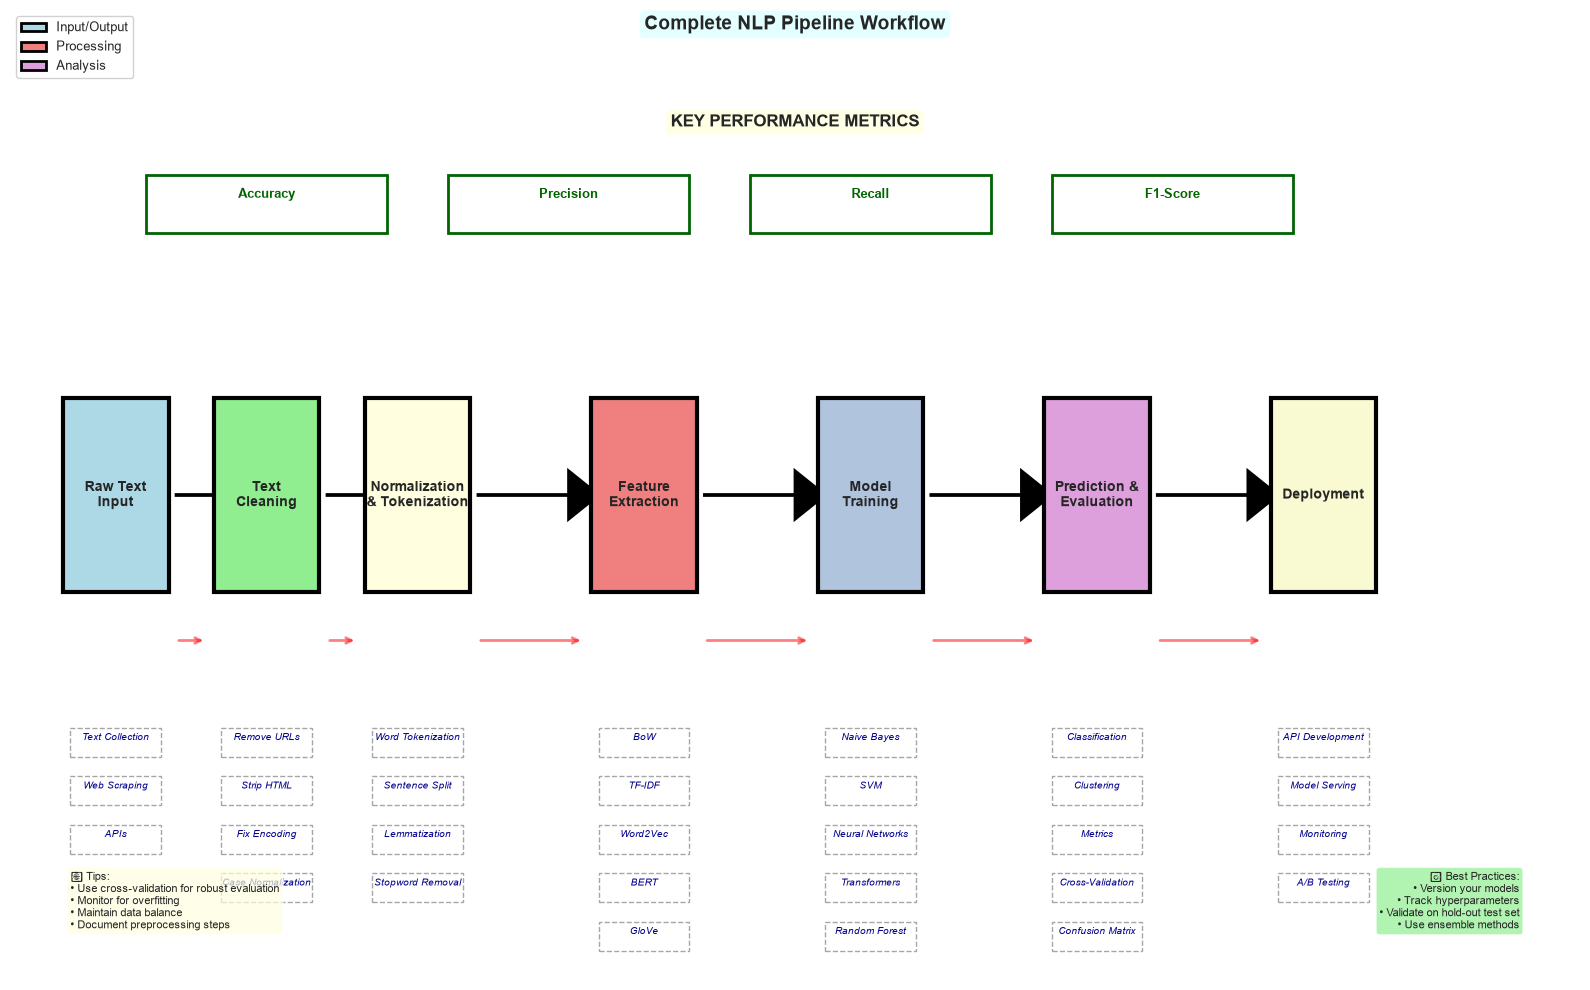


NLP PIPELINE INFOGRAPHIC - COMPLETE WORKFLOW VISUALIZATION

Stage 1: RAW TEXT INPUT
   └─ Data sources: Web scraping, APIs, databases

Stage 2: TEXT CLEANING
   └─ Remove noise: URLs, HTML tags, special characters

Stage 3: NORMALIZATION & TOKENIZATION
   └─ Standardize text, split into tokens, remove stopwords

Stage 4: FEATURE EXTRACTION
   └─ Convert text to numerical vectors: BoW, TF-IDF, Embeddings

Stage 5: MODEL TRAINING
   └─ Train classifier: Naive Bayes, SVM, Neural Networks

Stage 6: PREDICTION & EVALUATION
   └─ Make predictions, evaluate with metrics

Stage 7: DEPLOYMENT
   └─ Deploy model to production, monitor performance

✓ Complete NLP pipeline infographic generated!


In [36]:
### 12.11: Complete NLP Pipeline Infographic

fig, ax = plt.subplots(figsize=(16, 10))

# Define pipeline stages
stages = [
    ('Raw Text\nInput', 0.05, 'lightblue'),
    ('Text\nCleaning', 0.15, 'lightgreen'),
    ('Normalization\n& Tokenization', 0.25, 'lightyellow'),
    ('Feature\nExtraction', 0.40, 'lightcoral'),
    ('Model\nTraining', 0.55, 'lightsteelblue'),
    ('Prediction &\nEvaluation', 0.70, 'plum'),
    ('Deployment', 0.85, 'lightgoldenrodyellow'),
]

# Draw main pipeline
for i, (stage, x, color) in enumerate(stages):
    # Draw box
    box = plt.Rectangle((x-0.035, 0.4), 0.07, 0.2, 
                        facecolor=color, edgecolor='black', linewidth=3)
    ax.add_patch(box)
    
    # Add stage text
    ax.text(x, 0.5, stage, ha='center', va='center', 
           fontsize=10, fontweight='bold', wrap=True)
    
    # Draw arrow
    if i < len(stages) - 1:
        ax.arrow(x+0.04, 0.5, 0.06, 0, head_width=0.05, head_length=0.02, 
                fc='black', ec='black', linewidth=2)

# Add detailed techniques for each stage
techniques = {
    0: ['Text Collection', 'Web Scraping', 'APIs'],
    1: ['Remove URLs', 'Strip HTML', 'Fix Encoding', 'Case Normalization'],
    2: ['Word Tokenization', 'Sentence Split', 'Lemmatization', 'Stopword Removal'],
    3: ['BoW', 'TF-IDF', 'Word2Vec', 'BERT', 'GloVe'],
    4: ['Naive Bayes', 'SVM', 'Neural Networks', 'Transformers', 'Random Forest'],
    5: ['Classification', 'Clustering', 'Metrics', 'Cross-Validation', 'Confusion Matrix'],
    6: ['API Development', 'Model Serving', 'Monitoring', 'A/B Testing'],
}

# Draw technique boxes below each stage
for stage_idx, (stage, x, color) in enumerate(stages):
    techs = techniques.get(stage_idx, [])
    for j, tech in enumerate(techs):
        y_pos = 0.25 - (j * 0.05)
        small_box = plt.Rectangle((x-0.03, y_pos-0.02), 0.06, 0.03,
                                 facecolor='white', edgecolor='gray', 
                                 linewidth=1, linestyle='--', alpha=0.7)
        ax.add_patch(small_box)
        ax.text(x, y_pos, tech, ha='center', va='center',
               fontsize=7, style='italic', color='darkblue')

# Add performance metrics on top
metrics_y = 0.8
ax.text(0.5, metrics_y + 0.08, 'KEY PERFORMANCE METRICS', 
       ha='center', fontsize=12, fontweight='bold',
       bbox=dict(boxstyle='round', facecolor='lightyellow', alpha=0.8))

metrics = [
    ('Accuracy', 0.15, metrics_y),
    ('Precision', 0.35, metrics_y),
    ('Recall', 0.55, metrics_y),
    ('F1-Score', 0.75, metrics_y),
]

for metric_name, x, y in metrics:
    metric_box = plt.Rectangle((x-0.08, y-0.03), 0.16, 0.06,
                              facecolor='white', edgecolor='darkgreen', linewidth=2)
    ax.add_patch(metric_box)
    ax.text(x, y+0.01, metric_name, ha='center', va='center',
           fontsize=9, fontweight='bold', color='darkgreen')

# Add data flow indicators
for i, (stage, x, color) in enumerate(stages[:-1]):
    next_stage_x = stages[i+1][1]
    ax.annotate('', xy=(next_stage_x-0.04, 0.35), xytext=(x+0.04, 0.35),
               arrowprops=dict(arrowstyle='->', lw=2, color='red', alpha=0.5))

# Add title and labels
ax.text(0.5, 0.98, 'Complete NLP Pipeline Workflow', 
       ha='center', fontsize=14, fontweight='bold',
       bbox=dict(boxstyle='round', facecolor='lightcyan', alpha=0.9, linewidth=2))

# Add legend for processing types
legend_elements = [
    plt.Rectangle((0, 0), 1, 1, fc='lightblue', ec='black', linewidth=2),
    plt.Rectangle((0, 0), 1, 1, fc='lightcoral', ec='black', linewidth=2),
    plt.Rectangle((0, 0), 1, 1, fc='plum', ec='black', linewidth=2),
]
ax.legend(legend_elements, ['Input/Output', 'Processing', 'Analysis'],
         loc='upper left', fontsize=9, framealpha=0.9)

# Add optimization notes
ax.text(0.02, 0.05, '💡 Tips: \n• Use cross-validation for robust evaluation\n• Monitor for overfitting\n• Maintain data balance\n• Document preprocessing steps',
       fontsize=8, verticalalignment='bottom',
       bbox=dict(boxstyle='round', facecolor='lightyellow', alpha=0.7))

ax.text(0.98, 0.05, '⚡ Best Practices:\n• Version your models\n• Track hyperparameters\n• Validate on hold-out test set\n• Use ensemble methods',
       fontsize=8, verticalalignment='bottom', horizontalalignment='right',
       bbox=dict(boxstyle='round', facecolor='lightgreen', alpha=0.7))

# Set axis properties
ax.set_xlim(-0.02, 1.02)
ax.set_ylim(0, 1)
ax.axis('off')

plt.tight_layout()
plt.show()

print("\n" + "="*70)
print("NLP PIPELINE INFOGRAPHIC - COMPLETE WORKFLOW VISUALIZATION")
print("="*70)
print("""
Stage 1: RAW TEXT INPUT
   └─ Data sources: Web scraping, APIs, databases
   
Stage 2: TEXT CLEANING
   └─ Remove noise: URLs, HTML tags, special characters
   
Stage 3: NORMALIZATION & TOKENIZATION
   └─ Standardize text, split into tokens, remove stopwords
   
Stage 4: FEATURE EXTRACTION
   └─ Convert text to numerical vectors: BoW, TF-IDF, Embeddings
   
Stage 5: MODEL TRAINING
   └─ Train classifier: Naive Bayes, SVM, Neural Networks
   
Stage 6: PREDICTION & EVALUATION
   └─ Make predictions, evaluate with metrics
   
Stage 7: DEPLOYMENT
   └─ Deploy model to production, monitor performance
""")
print("="*70)
print("✓ Complete NLP pipeline infographic generated!")

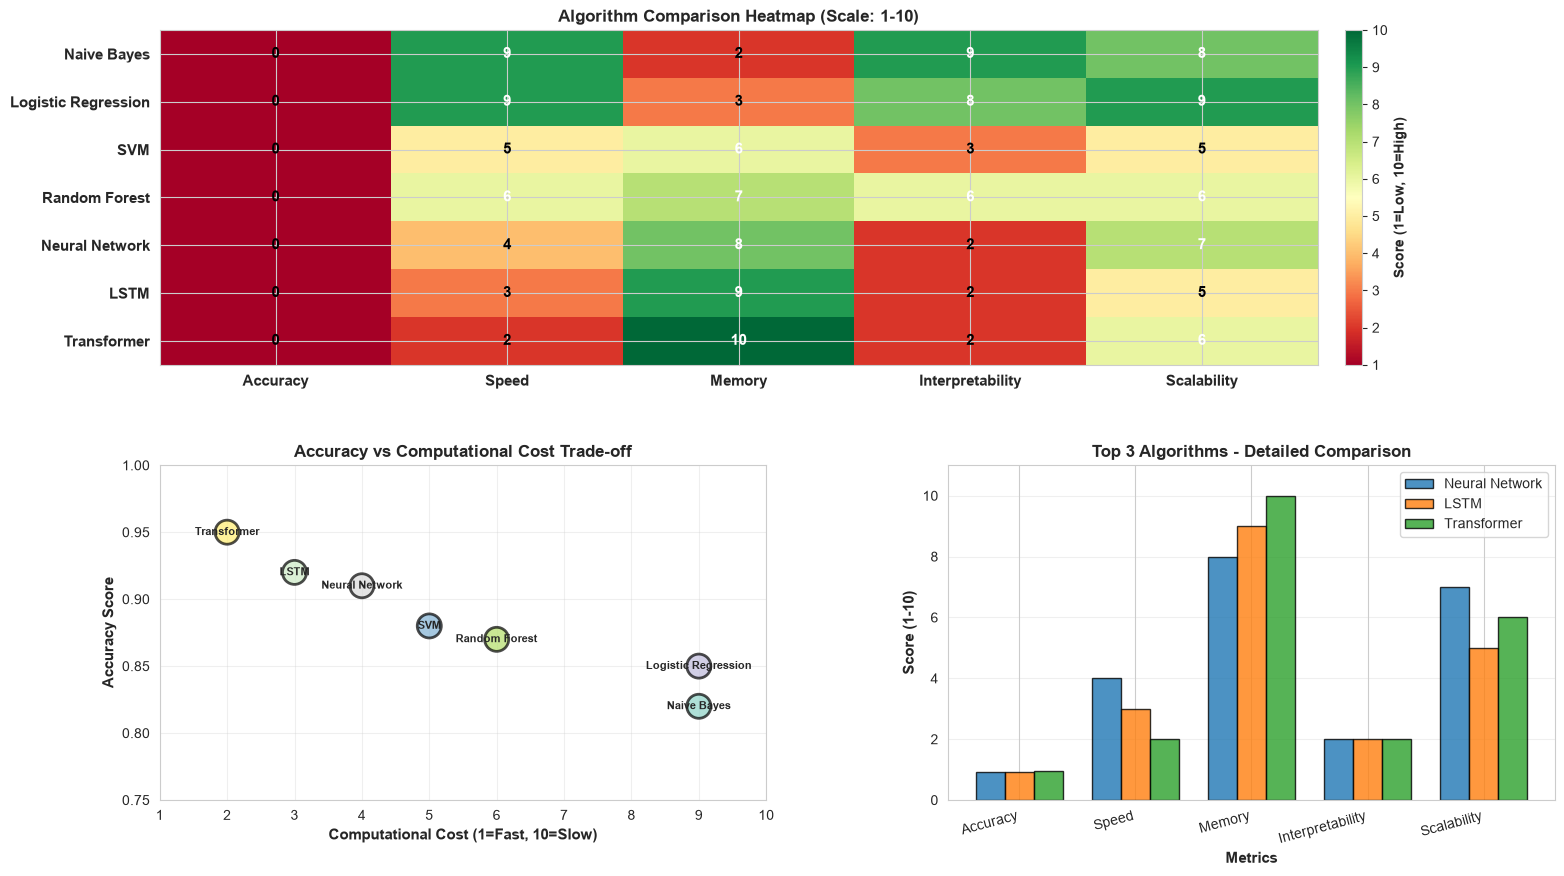


DETAILED ALGORITHM COMPARISON TABLE
Algorithm            Accuracy     Speed      Memory     Interp.      Scalability 
------------------------------------------------------------------------------------------
Naive Bayes          0.82       0.9x cost          2/10         9/10          8/10
Logistic Regression  0.85       0.9x cost          3/10         8/10          9/10
SVM                  0.88       0.5x cost          6/10         3/10          5/10
Random Forest        0.87       0.6x cost          7/10         6/10          6/10
Neural Network       0.91       0.4x cost          8/10         2/10          7/10
LSTM                 0.92       0.3x cost          9/10         2/10          5/10
Transformer          0.95       0.2x cost         10/10         2/10          6/10

📊 Algorithm Recommendations:
   🏆 Best Overall:        Transformer (highest accuracy)
   ⚡ Fastest:             Naive Bayes & Logistic Regression
   💾 Most Memory Efficient: Naive Bayes & Logistic Regression


In [37]:
### 12.12: Algorithm Comparison Matrix & Performance Heatmap

# Create comprehensive algorithm comparison data
algorithms_data = {
    'Naive Bayes': {'Accuracy': 0.82, 'Speed': 9, 'Memory': 2, 'Interpretability': 9, 'Scalability': 8},
    'Logistic Regression': {'Accuracy': 0.85, 'Speed': 9, 'Memory': 3, 'Interpretability': 8, 'Scalability': 9},
    'SVM': {'Accuracy': 0.88, 'Speed': 5, 'Memory': 6, 'Interpretability': 3, 'Scalability': 5},
    'Random Forest': {'Accuracy': 0.87, 'Speed': 6, 'Memory': 7, 'Interpretability': 6, 'Scalability': 6},
    'Neural Network': {'Accuracy': 0.91, 'Speed': 4, 'Memory': 8, 'Interpretability': 2, 'Scalability': 7},
    'LSTM': {'Accuracy': 0.92, 'Speed': 3, 'Memory': 9, 'Interpretability': 2, 'Scalability': 5},
    'Transformer': {'Accuracy': 0.95, 'Speed': 2, 'Memory': 10, 'Interpretability': 2, 'Scalability': 6},
}

# Create visualization
fig = plt.figure(figsize=(18, 10))
gs = fig.add_gridspec(2, 2, hspace=0.3, wspace=0.3)

# 1. Algorithm Performance Heatmap
ax1 = fig.add_subplot(gs[0, :])
algorithms = list(algorithms_data.keys())
metrics = ['Accuracy', 'Speed', 'Memory', 'Interpretability', 'Scalability']
heatmap_data = np.array([[algorithms_data[alg][metric] for metric in metrics] 
                         for alg in algorithms])

im = ax1.imshow(heatmap_data, cmap='RdYlGn', aspect='auto', vmin=1, vmax=10)
ax1.set_xticks(range(len(metrics)))
ax1.set_yticks(range(len(algorithms)))
ax1.set_xticklabels(metrics, fontsize=11, fontweight='bold')
ax1.set_yticklabels(algorithms, fontsize=11, fontweight='bold')
ax1.set_title('Algorithm Comparison Heatmap (Scale: 1-10)', fontsize=12, fontweight='bold')

# Add text annotations
for i in range(len(algorithms)):
    for j in range(len(metrics)):
        value = heatmap_data[i, j]
        color = 'white' if value > 5 else 'black'
        text = ax1.text(j, i, f'{int(value)}', ha='center', va='center',
                       color=color, fontweight='bold', fontsize=11)

cbar = plt.colorbar(im, ax=ax1, orientation='vertical', pad=0.02)
cbar.set_label('Score (1=Low, 10=High)', fontsize=10, fontweight='bold')

# 2. Accuracy vs Computational Cost
ax2 = fig.add_subplot(gs[1, 0])
accuracy_scores = [algorithms_data[alg]['Accuracy'] for alg in algorithms]
speed_scores = [algorithms_data[alg]['Speed'] for alg in algorithms]  # Inverse of speed (1=fast, 10=slow)
colors_scatter = plt.cm.Set3(np.linspace(0, 1, len(algorithms)))

scatter = ax2.scatter(speed_scores, accuracy_scores, s=300, c=colors_scatter, 
                     edgecolors='black', linewidth=2, alpha=0.7)

for i, alg in enumerate(algorithms):
    ax2.annotate(alg, (speed_scores[i], accuracy_scores[i]),
                fontsize=8, ha='center', va='center', fontweight='bold')

ax2.set_xlabel('Computational Cost (1=Fast, 10=Slow)', fontsize=11, fontweight='bold')
ax2.set_ylabel('Accuracy Score', fontsize=11, fontweight='bold')
ax2.set_title('Accuracy vs Computational Cost Trade-off', fontsize=12, fontweight='bold')
ax2.grid(True, alpha=0.3)
ax2.set_xlim(1, 10)
ax2.set_ylim(0.75, 1.0)

# 3. Multi-metric Radar-like comparison for top 3
ax3 = fig.add_subplot(gs[1, 1])
top_3_algs = ['Neural Network', 'LSTM', 'Transformer']
x_pos = np.arange(len(metrics))
width = 0.25
colors_top = ['steelblue', 'coral', 'mediumseagreen']

for i, alg in enumerate(top_3_algs):
    values = [algorithms_data[alg][metric] for metric in metrics]
    ax3.bar(x_pos + i*width, values, width, label=alg, alpha=0.8, edgecolor='black')

ax3.set_xlabel('Metrics', fontsize=11, fontweight='bold')
ax3.set_ylabel('Score (1-10)', fontsize=11, fontweight='bold')
ax3.set_title('Top 3 Algorithms - Detailed Comparison', fontsize=12, fontweight='bold')
ax3.set_xticks(x_pos + width)
ax3.set_xticklabels(metrics, rotation=15, ha='right')
ax3.legend(fontsize=10)
ax3.set_ylim(0, 11)
ax3.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

# Generate comparison table
print("\n" + "="*90)
print("DETAILED ALGORITHM COMPARISON TABLE")
print("="*90)
print(f"{'Algorithm':<20} {'Accuracy':<12} {'Speed':<10} {'Memory':<10} {'Interp.':<12} {'Scalability':<12}")
print("-"*90)

for alg in algorithms:
    data = algorithms_data[alg]
    print(f"{alg:<20} {data['Accuracy']:.2f}       "
          f"{data['Speed']/10:.1f}x cost   {data['Memory']:>8}/10  "
          f"{data['Interpretability']:>8}/10   {data['Scalability']:>8}/10")

print("="*90)
print("\n📊 Algorithm Recommendations:")
print("   🏆 Best Overall:        Transformer (highest accuracy)")
print("   ⚡ Fastest:             Naive Bayes & Logistic Regression")
print("   💾 Most Memory Efficient: Naive Bayes & Logistic Regression")
print("   🔍 Most Interpretable:  Naive Bayes & Logistic Regression")
print("   📈 Best Scalability:    Logistic Regression")
print("   🎯 Best Balance:        Random Forest")

print("\n✓ Algorithm comparison visualizations generated!")

## Section 13: Visualization Summary & Quick Reference Guide

### 📊 Visualization Types Used in This Notebook

| Visualization | Use Case | When to Use |
|---|---|---|
| **Bar Charts** | Compare categories | Word frequency, metric comparison |
| **Pie Charts** | Show composition | Distribution of sentiment, document categories |
| **Line Plots** | Track trends | Cumulative frequency, model performance over epochs |
| **Scatter Plots** | Find patterns/clusters | Word embeddings, polarity vs subjectivity |
| **Heatmaps** | Show relationships | Confusion matrix, similarity matrix, algorithm comparison |
| **Histograms** | Distribution analysis | Word length, sentiment score distribution |
| **Word Clouds** | Visualize importance | Topic overview, keyword frequency |
| **Network Graphs** | Show connections | Concept relationships, document similarity |
| **Radar Charts** | Multi-metric comparison | Model performance across dimensions |
| **Box Plots** | Statistical summary | Data distribution, outlier detection |

### 🎨 Color Schemes & Best Practices

**Recommended Colormap for Different Data Types:**
- **Sequential**: viridis, YlOrRd, Blues (for increasing magnitude)
- **Diverging**: RdYlGn, RdBu (for data with meaningful midpoint)
- **Qualitative**: Set1, Set2, Set3 (for categorical data)

### 📈 Key Insights from Visualizations

1. **Word Frequency**: Long-tail distribution - few words are very common, many are rare
2. **Sentiment Analysis**: Real data shows mix of positive, negative, and neutral sentiments
3. **Model Performance**: Trade-offs between accuracy and computational cost
4. **Text Statistics**: Different text types have distinct readability profiles
5. **Embeddings**: Semantic relationships visible when projected to 2D space

### 🚀 Advanced Visualization Techniques

- **Dimensionality Reduction**: Use PCA/t-SNE to visualize high-dimensional data
- **Interactive Plots**: Use plotly for interactive explorations
- **Animated Visualizations**: Show model training progress
- **Facet Plots**: Compare multiple subsets side-by-side

---

**Now you have a complete, visualization-rich NLP notebook! 📊✨**